# Graphs for steps 3-7

Every cell reads its inputs from `/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise` (set in `DATA_DIRS` in the setup cell; the setup cell prints which files were found) and draws its figures with a caption under each figure (what it shows + inference). Run the setup cell first; a missing file only skips the figures that need it. PNGs are saved to `/kaggle/working/.../figs` (`DLA_DIR/figs`, or `./figs` if `DLA_DIR` is not defined).

In [2]:
# GRAPHS 0. SETUP (run once, before any graph cell): style, file finder, caption helper, shared data loaders
import os, glob, re, random, textwrap, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, pearsonr, ks_2samp, norm
warnings.filterwarnings("ignore")
FIG_DIR = (f"{DLA_DIR}/figs" if "DLA_DIR" in globals() else "figs"); os.makedirs(FIG_DIR, exist_ok=True)
COL = dict(pres="#2a6fdb", absn="#e07b00", head="#6b7a8f", mlp="#c0392b", good="#2e8b57", bad="#c0392b", grey="#8a8a8a", ev="#c0392b", op="#2a6fdb", br="#8e44ad", rnd="#9aa5b1", ink="#222222")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10, "font.size": 9, "legend.frameon": False})
_cache = {}
DATA_DIRS = globals().get("DATA_DIRS", [
    "/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise",                 # all inputs are read from this dataset
    # "/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise-step7",         # uncomment after the standalone step 7 notebook has run (patch_*.csv)
])
def find(name):
    hits = []
    for r in DATA_DIRS: hits += glob.glob(f"{r}/{name}") + glob.glob(f"{r}/**/{name}", recursive=True)
    return max(hits, key=os.path.getmtime) if hits else None
def load(name):
    if name not in _cache:
        p = find(name)
        if p is None: raise FileNotFoundError(f"{name} not found in DLA_DIR, /kaggle/working or /kaggle/input")
        _cache[name] = np.load(p, allow_pickle=True) if name.endswith(".npz") else pd.read_csv(p); print(f"  loaded {p}")
    return _cache[name]
def auc(x, pos):
    x = np.asarray(x, float); pos = np.asarray(pos, bool); r = rankdata(x); n1 = pos.sum(); n0 = len(pos) - n1
    return float((r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
def roc(x, pos):
    o = np.argsort(-np.asarray(x, float)); p = np.asarray(pos, bool)[o]
    return np.r_[0, np.cumsum(~p) / (~p).sum()], np.r_[0, np.cumsum(p) / p.sum()]
def finish(fig, name, what, inference):
    """adds a caption box (what it shows + inference) under the figure, saves a PNG and shows it"""
    w, h = fig.get_size_inches()
    txt = "\n".join(textwrap.fill(p, width=int(w * 12.5)) for p in (f"What it shows: {what}", f"Inference: {inference}"))
    cap = 0.19 * (txt.count("\n") + 1) + 0.3
    fig.set_size_inches(w, h + cap); fig.tight_layout(rect=[0, cap / (h + cap), 1, 1])
    fig.text(0.012, 0.01, txt, ha="left", va="bottom", fontsize=8.8, linespacing=1.35, color=COL["ink"], bbox=dict(boxstyle="round,pad=0.45", fc="#f4f1ea", ec="#d8d2c2"))
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=140, bbox_inches="tight"); plt.show(); plt.close(fig)
def run(fn):
    try: fn()
    except Exception as ex: print(f"[skipped {fn.__name__}] {type(ex).__name__}: {ex}"); plt.close("all")
    return fn
def prep5():
    """attribution-patching data (step 5): per-question atp / direct (DLA clean-minus-corrupted) for 1024 heads + 32 MLPs"""
    if "p5" not in _cache:
        z = load("atp_results.npz"); gt = np.array(z["gt"]).astype(str); yes = gt == "yes"; N = len(gt)
        A = np.concatenate([z["atp_a"].reshape(N, -1), z["atp_m"]], 1); D = np.concatenate([z["dla_a"].reshape(N, -1), z["dla_m"]], 1)
        names = np.array([f"L{l}H{h}" for l in range(32) for h in range(32)] + [f"L{l}.mlp" for l in range(32)])
        ldc, ldn = z["ld_clean"].astype(float), z["ld_corr"].astype(float)
        out = np.where(yes & (ldc > 0), "TP", np.where(~yes & (ldc <= 0), "TN", np.where(ldc > 0, "FP", "FN")))
        _cache["p5"] = dict(yes=yes, sg=np.where(yes, 1.0, -1.0), ldc=ldc, ldn=ldn, E=ldc - ldn, A=A, D=D, names=names, N=N, out=out)
    return _cache["p5"]
EV_L, OP_L, BR_L = [16, 17, 18, 20, 23], [21, 24, 27], [28, 30, 31]
print("figures are saved to", FIG_DIR)
print("reading inputs from:", DATA_DIRS)
for _f in ["atp_results.npz", "ablation_table.csv", "meanablation_table.csv", "meanablation_results.npz", "mlp_localisation_table.csv", "mlp_localisation.npz", "patch_last_position.csv", "patch_kv.csv"]:
    print(f"  {_f:30s}", "found" if find(_f) else "MISSING (graphs that need it will be skipped)")


figures are saved to figs
reading inputs from: ['/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise']
  atp_results.npz                found
  ablation_table.csv             found
  meanablation_table.csv         found
  meanablation_results.npz       found
  mlp_localisation_table.csv     found
  mlp_localisation.npz           found
  patch_last_position.csv        found
  patch_kv.csv                   found


## Step 3: corrupted-image control (needs `atp_results.npz`)

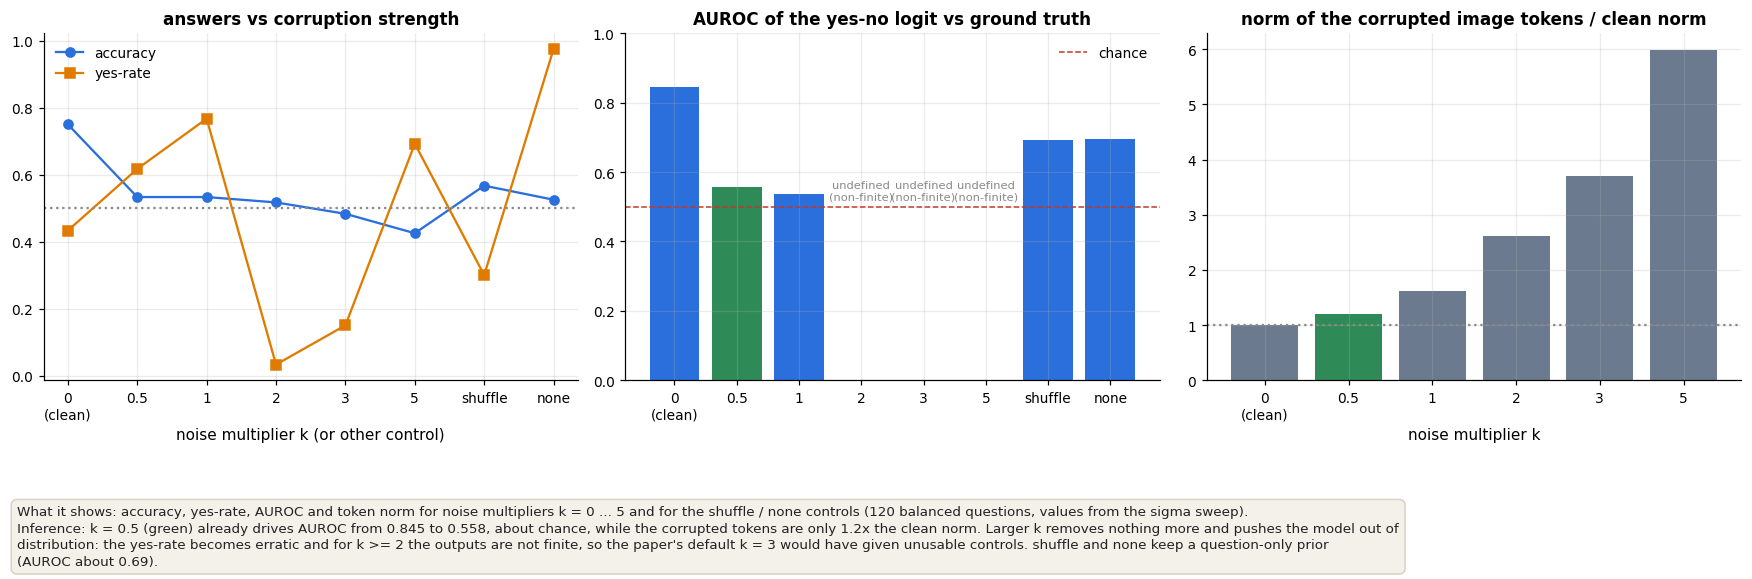

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/atp_results.npz


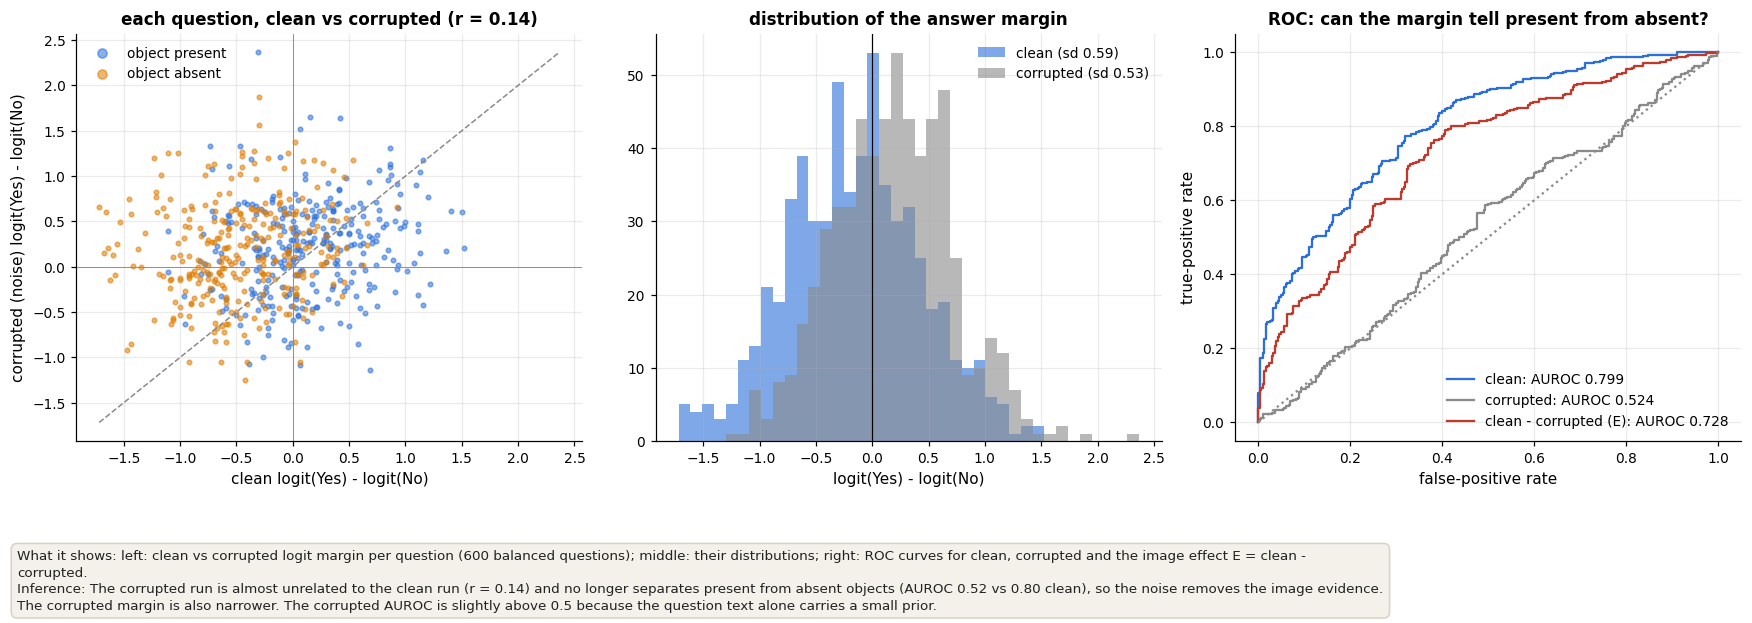

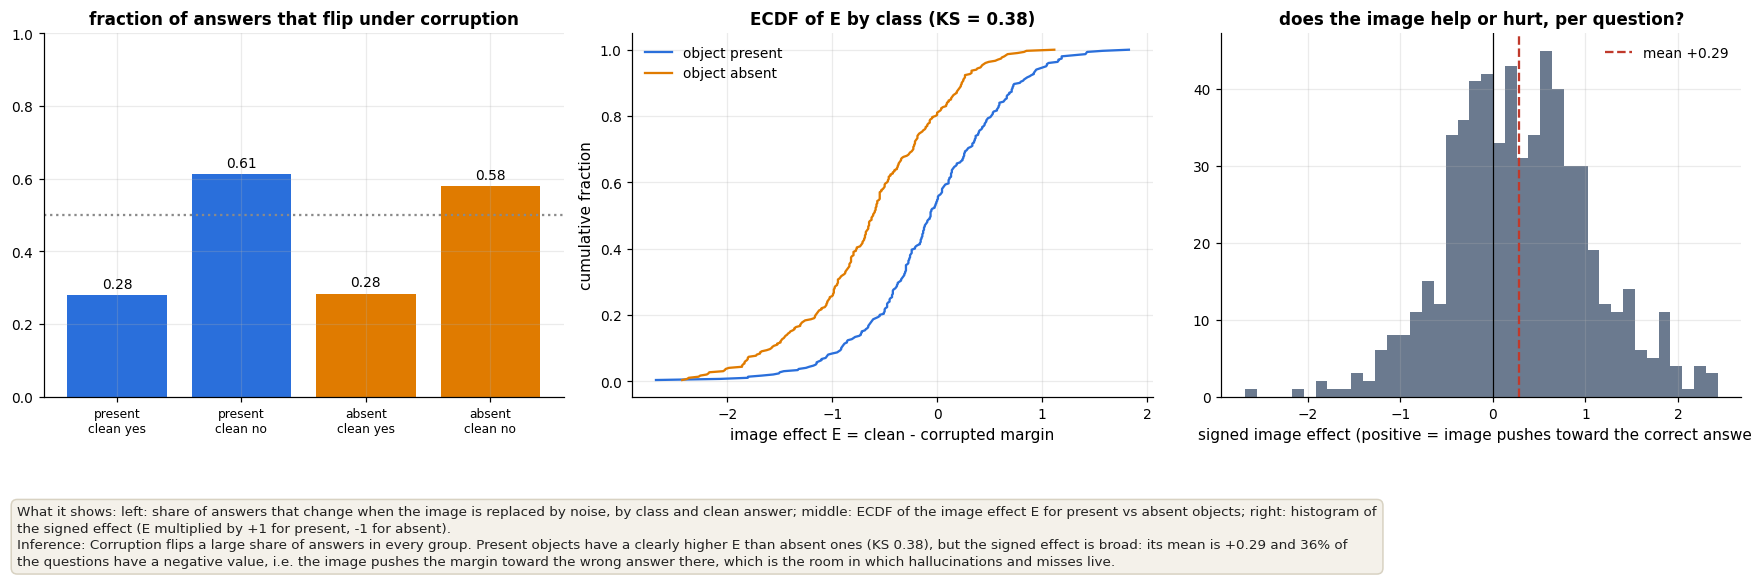

In [2]:
# GRAPHS 3. corrupted-image control: choice of the noise level, and what the corruption does to the model's answers
@run
def g3_sigma_sweep():
    lab = ["0\n(clean)", "0.5", "1", "2", "3", "5", "shuffle", "none"]
    acc = [.750, .533, .533, .517, .483, .425, .567, .525]; yr = [.433, .617, .767, .033, .150, .692, .300, .975]
    au = [.845, .558, .536, np.nan, np.nan, np.nan, .692, .695]; nr = [1, 1.21, 1.62, 2.62, 3.71, 5.99]
    x = np.arange(len(lab)); fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax[0].plot(x, acc, "o-", c=COL["pres"], label="accuracy"); ax[0].plot(x, yr, "s-", c=COL["absn"], label="yes-rate"); ax[0].axhline(.5, c=COL["grey"], ls=":")
    ax[0].set_xticks(x); ax[0].set_xticklabels(lab); ax[0].set_xlabel("noise multiplier k (or other control)"); ax[0].set_title("answers vs corruption strength"); ax[0].legend()
    c = [COL["grey"] if np.isnan(v) else (COL["good"] if i == 1 else COL["pres"]) for i, v in enumerate(au)]
    ax[1].bar(x, [0 if np.isnan(v) else v for v in au], color=c); ax[1].axhline(.5, c=COL["bad"], ls="--", lw=1, label="chance")
    for i, v in enumerate(au):
        if np.isnan(v): ax[1].text(i, .52, "undefined\n(non-finite)", ha="center", fontsize=7.5, color=COL["grey"])
    ax[1].set_ylim(0, 1); ax[1].set_xticks(x); ax[1].set_xticklabels(lab); ax[1].set_title("AUROC of the yes-no logit vs ground truth"); ax[1].legend(loc="upper right")
    ax[2].bar(np.arange(6), nr, color=[COL["good"] if i == 1 else COL["head"] for i in range(6)]); ax[2].axhline(1, c=COL["grey"], ls=":")
    ax[2].set_xticks(np.arange(6)); ax[2].set_xticklabels(lab[:6]); ax[2].set_title("norm of the corrupted image tokens / clean norm"); ax[2].set_xlabel("noise multiplier k")
    finish(fig, "g3_sigma_sweep", "accuracy, yes-rate, AUROC and token norm for noise multipliers k = 0 ... 5 and for the shuffle / none controls (120 balanced questions, values from the sigma sweep).",
           "k = 0.5 (green) already drives AUROC from 0.845 to 0.558, about chance, while the corrupted tokens are only 1.2x the clean norm. Larger k removes nothing more and pushes the model out of distribution: the yes-rate becomes erratic and for k >= 2 the outputs are not finite, so the paper's default k = 3 would have given unusable controls. shuffle and none keep a question-only prior (AUROC about 0.69).")
@run
def g3_clean_vs_corrupted():
    P = prep5(); y = P["yes"]; ldc, ldn = P["ldc"], P["ldn"]; r = np.corrcoef(ldc, ldn)[0, 1]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    ax[0].scatter(ldc[y], ldn[y], s=9, alpha=.55, c=COL["pres"], label="object present"); ax[0].scatter(ldc[~y], ldn[~y], s=9, alpha=.55, c=COL["absn"], label="object absent")
    lim = [min(ldc.min(), ldn.min()), max(ldc.max(), ldn.max())]; ax[0].plot(lim, lim, c=COL["grey"], ls="--", lw=1); ax[0].axhline(0, c=COL["grey"], lw=.6); ax[0].axvline(0, c=COL["grey"], lw=.6)
    ax[0].set_xlabel("clean logit(Yes) - logit(No)"); ax[0].set_ylabel("corrupted (noise) logit(Yes) - logit(No)"); ax[0].set_title(f"each question, clean vs corrupted (r = {r:.2f})"); ax[0].legend(markerscale=2)
    b = np.linspace(min(ldc.min(), ldn.min()), max(ldc.max(), ldn.max()), 40)
    ax[1].hist(ldc, b, alpha=.6, color=COL["pres"], label=f"clean (sd {ldc.std():.2f})"); ax[1].hist(ldn, b, alpha=.6, color=COL["grey"], label=f"corrupted (sd {ldn.std():.2f})"); ax[1].axvline(0, c="k", lw=.8)
    ax[1].set_xlabel("logit(Yes) - logit(No)"); ax[1].set_title("distribution of the answer margin"); ax[1].legend()
    for lbl, v, c in [("clean", ldc, COL["pres"]), ("corrupted", ldn, COL["grey"]), ("clean - corrupted (E)", P["E"], COL["mlp"])]:
        f, t = roc(v, y); ax[2].plot(f, t, c=c, label=f"{lbl}: AUROC {auc(v, y):.3f}")
    ax[2].plot([0, 1], [0, 1], c=COL["grey"], ls=":"); ax[2].set_xlabel("false-positive rate"); ax[2].set_ylabel("true-positive rate"); ax[2].set_title("ROC: can the margin tell present from absent?"); ax[2].legend(loc="lower right")
    finish(fig, "g3_clean_vs_corrupted", f"left: clean vs corrupted logit margin per question ({len(ldc)} balanced questions); middle: their distributions; right: ROC curves for clean, corrupted and the image effect E = clean - corrupted.",
           f"The corrupted run is almost unrelated to the clean run (r = {r:.2f}) and no longer separates present from absent objects (AUROC {auc(ldn, y):.2f} vs {auc(ldc, y):.2f} clean), so the noise removes the image evidence. The corrupted margin is also narrower. The corrupted AUROC is slightly above 0.5 because the question text alone carries a small prior.")
@run
def g3_flips_and_ecdf():
    P = prep5(); y = P["yes"]; ldc, ldn, E = P["ldc"], P["ldn"], P["E"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    names = ["present, clean yes", "present, clean no", "absent, clean yes", "absent, clean no"]; masks = [y & (ldc > 0), y & (ldc <= 0), ~y & (ldc > 0), ~y & (ldc <= 0)]
    flip = [float(((ldn > 0) != (ldc > 0))[m].mean()) for m in masks]; ax[0].bar(range(4), flip, color=[COL["pres"], COL["pres"], COL["absn"], COL["absn"]]); ax[0].set_xticks(range(4)); ax[0].set_xticklabels([n.replace(", ", "\n") for n in names], fontsize=8)
    ax[0].set_ylim(0, 1); ax[0].set_title("fraction of answers that flip under corruption"); ax[0].axhline(.5, c=COL["grey"], ls=":")
    for i, v in enumerate(flip): ax[0].text(i, v + .02, f"{v:.2f}", ha="center")
    for v, lbl, c in [(E[y], "object present", COL["pres"]), (E[~y], "object absent", COL["absn"])]:
        xs = np.sort(v); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), c=c, label=lbl)
    ks = ks_2samp(E[y], E[~y]); ax[1].set_xlabel("image effect E = clean - corrupted margin"); ax[1].set_ylabel("cumulative fraction"); ax[1].set_title(f"ECDF of E by class (KS = {ks.statistic:.2f})"); ax[1].legend()
    sh = P["sg"] * E; ax[2].hist(sh, 40, color=COL["head"]); ax[2].axvline(0, c="k", lw=.8); ax[2].axvline(sh.mean(), c=COL["bad"], ls="--", label=f"mean {sh.mean():+.2f}")
    ax[2].set_xlabel("signed image effect (positive = image pushes toward the correct answer)"); ax[2].set_title("does the image help or hurt, per question?"); ax[2].legend()
    finish(fig, "g3_flips_and_ecdf", f"left: share of answers that change when the image is replaced by noise, by class and clean answer; middle: ECDF of the image effect E for present vs absent objects; right: histogram of the signed effect (E multiplied by +1 for present, -1 for absent).",
           f"Corruption flips a large share of answers in every group. Present objects have a clearly higher E than absent ones (KS {ks.statistic:.2f}), but the signed effect is broad: its mean is {sh.mean():+.2f} and {(sh < 0).mean():.0%} of the questions have a negative value, i.e. the image pushes the margin toward the wrong answer there, which is the room in which hallucinations and misses live.")


## Step 4: last-position ablations (needs `ablation_table.csv`)

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/ablation_table.csv


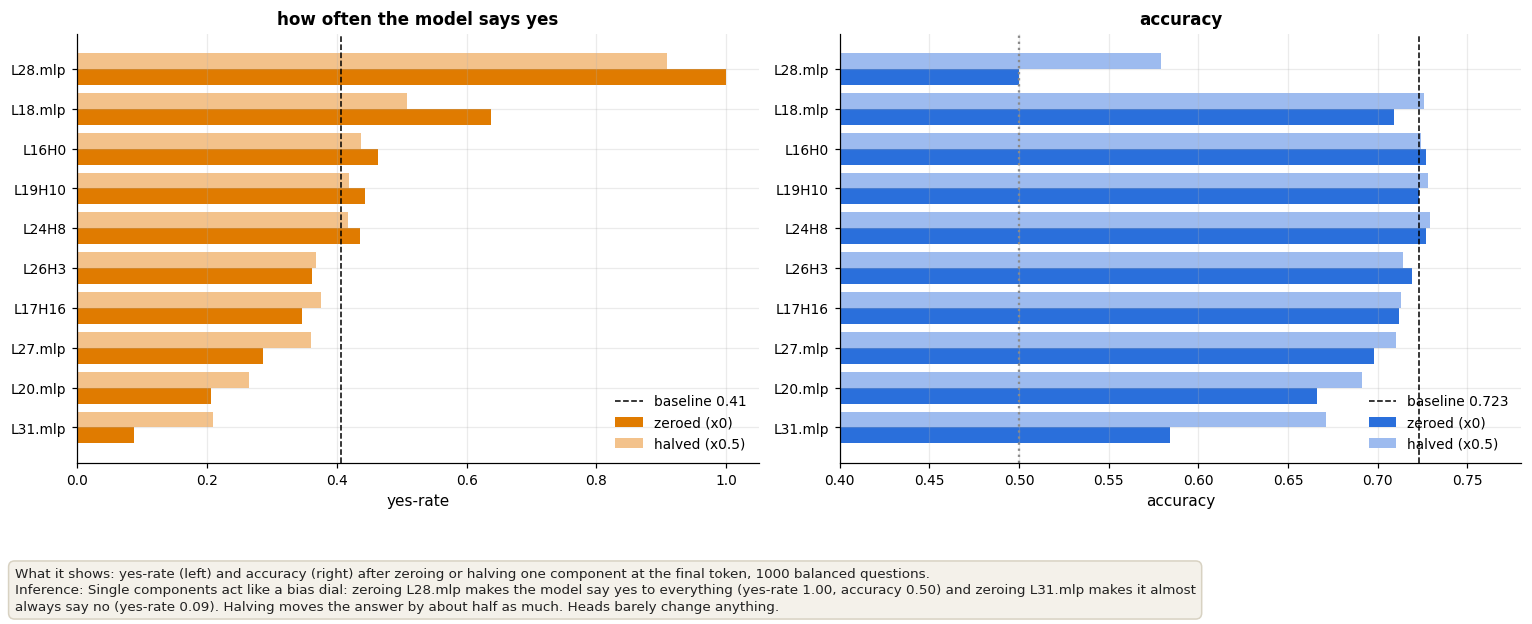

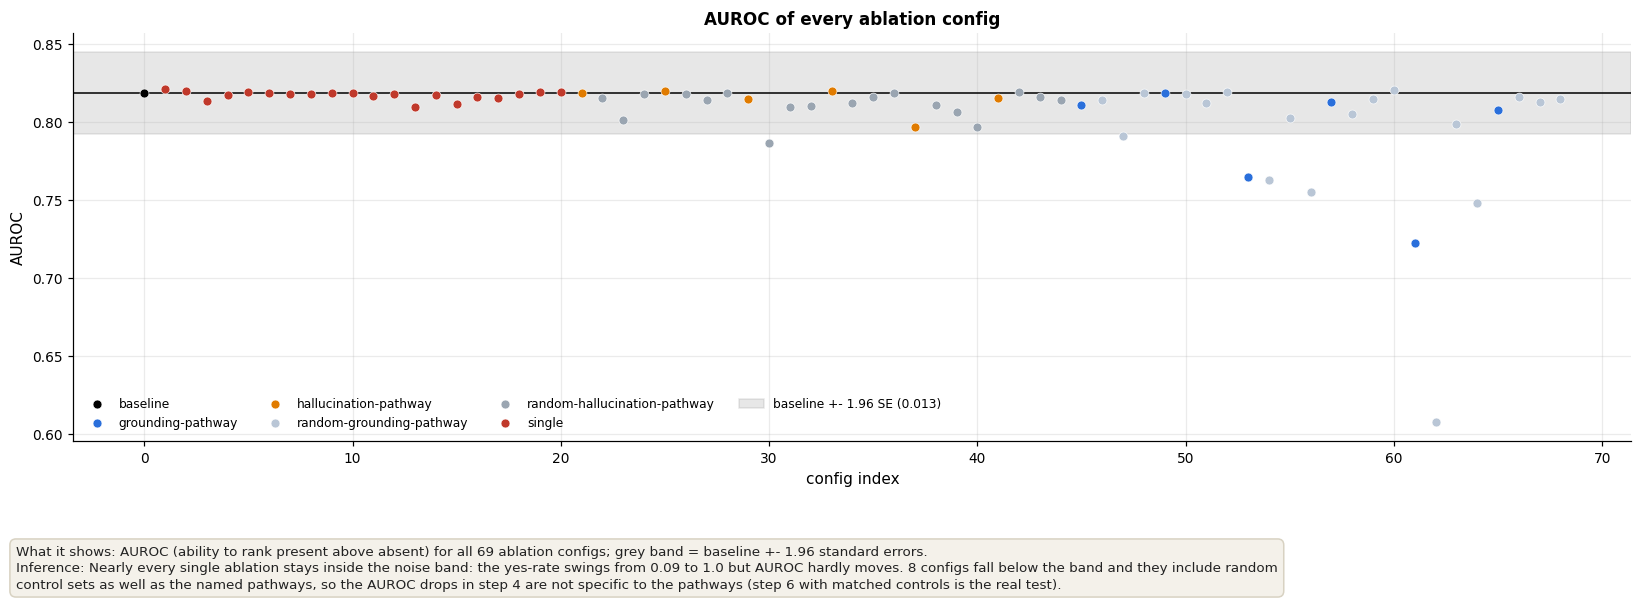

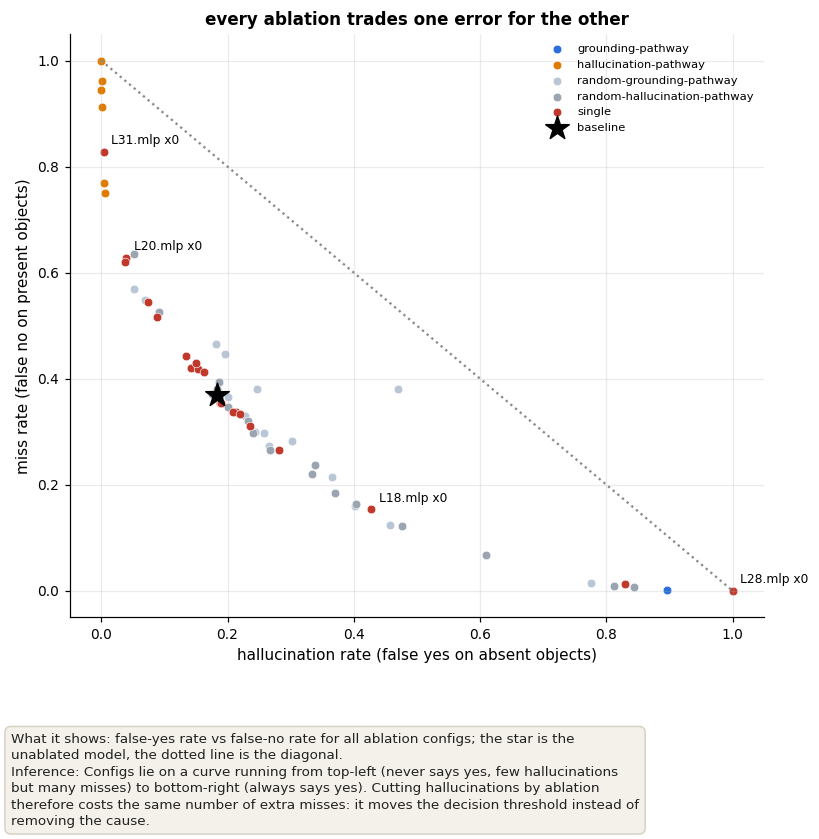

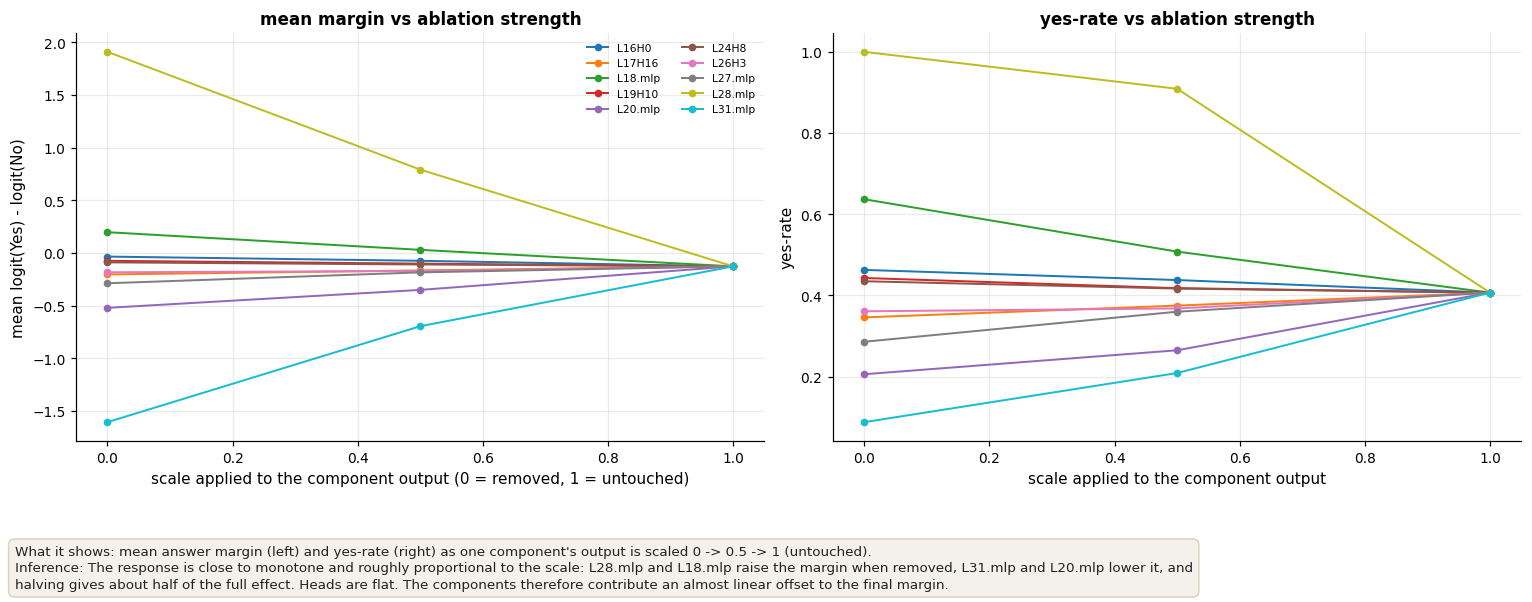

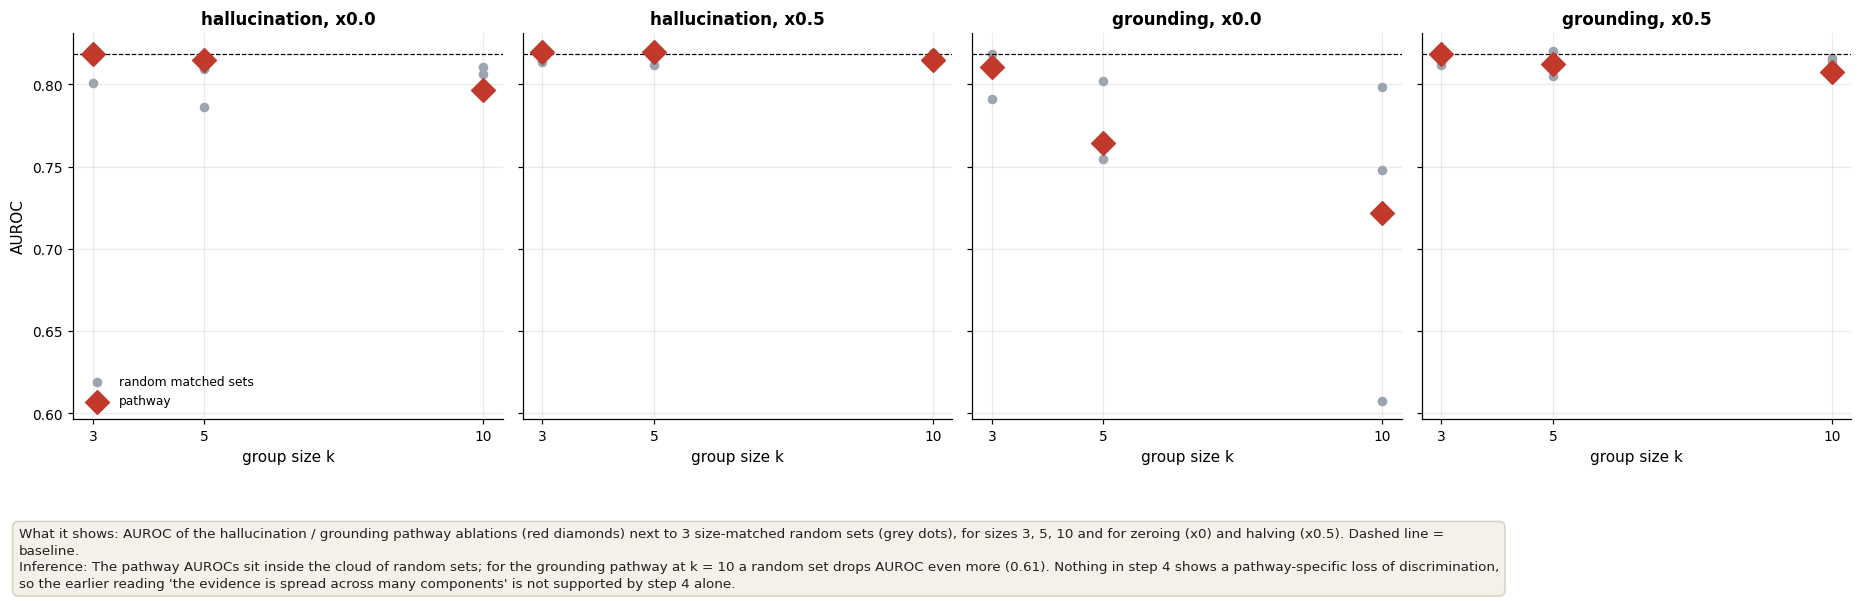

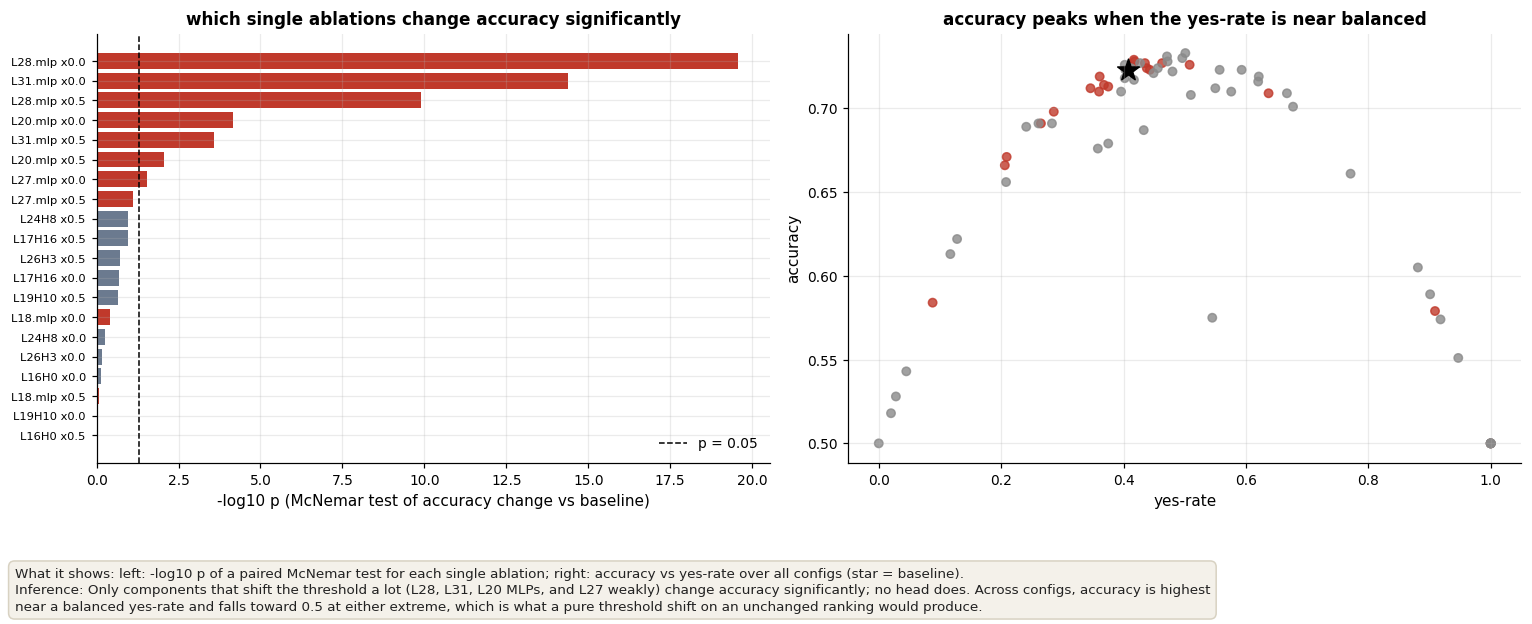

In [3]:
# GRAPHS 4. step 4: last-position ablations (zero / halve one component or a group), reading ablation_table.csv
def _t4():
    t = load("ablation_table.csv").copy(); t["is_rand"] = t.group.str.startswith("random"); return t
def _hm_se(a, n1=500, n0=500): # Hanley-McNeil standard error of an AUROC
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a); return float(np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0)))
@run
def g4_singles_bias():
    t = _t4(); b = t.iloc[0]; s = t[(t.group == "single") & (t.scale == 0.0)].sort_values("yes_rate")
    nm = s.label.str.replace(" x0.0", "", regex=False); half = t[(t.group == "single") & (t.scale == 0.5)]; half.index = half.label.str.replace(" x0.5", "", regex=False)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); y = np.arange(len(s))
    ax[0].barh(y - .2, s.yes_rate, .4, color=COL["absn"], label="zeroed (x0)"); ax[0].barh(y + .2, [half.loc[n, "yes_rate"] for n in nm], .4, color="#f3c28b", label="halved (x0.5)"); ax[0].axvline(b.yes_rate, c="k", ls="--", lw=1, label=f"baseline {b.yes_rate:.2f}")
    ax[0].set_yticks(y); ax[0].set_yticklabels(nm); ax[0].set_xlabel("yes-rate"); ax[0].set_title("how often the model says yes"); ax[0].legend(loc="lower right")
    ax[1].barh(y - .2, s.acc, .4, color=COL["pres"], label="zeroed (x0)"); ax[1].barh(y + .2, [half.loc[n, "acc"] for n in nm], .4, color="#9dbbef", label="halved (x0.5)"); ax[1].axvline(b.acc, c="k", ls="--", lw=1, label=f"baseline {b.acc:.3f}"); ax[1].axvline(.5, c=COL["grey"], ls=":")
    ax[1].set_yticks(y); ax[1].set_yticklabels(nm); ax[1].set_xlim(.4, .78); ax[1].set_xlabel("accuracy"); ax[1].set_title("accuracy"); ax[1].legend(loc="lower right")
    finish(fig, "g4_singles_bias", "yes-rate (left) and accuracy (right) after zeroing or halving one component at the final token, 1000 balanced questions.",
           f"Single components act like a bias dial: zeroing L28.mlp makes the model say yes to everything (yes-rate {s.yes_rate.max():.2f}, accuracy 0.50) and zeroing L31.mlp makes it almost always say no (yes-rate {s.yes_rate.min():.2f}). Halving moves the answer by about half as much. Heads barely change anything.")
@run
def g4_auroc_all():
    t = _t4(); b = t.iloc[0]; se = _hm_se(b.auroc); fig, ax = plt.subplots(1, 1, figsize=(15, 4.6))
    cmap = {"baseline": "k", "single": COL["mlp"], "hallucination-pathway": COL["absn"], "grounding-pathway": COL["pres"], "random-hallucination-pathway": COL["rnd"], "random-grounding-pathway": "#b9c6d6"}
    for g, d in t.groupby("group"): ax.scatter(d.index, d.auroc, s=34, c=cmap.get(g, COL["grey"]), label=g, edgecolor="white", lw=.4, zorder=3)
    ax.axhline(b.auroc, c="k", lw=1); ax.axhspan(b.auroc - 1.96 * se, b.auroc + 1.96 * se, color=COL["grey"], alpha=.2, label=f"baseline +- 1.96 SE ({se:.3f})")
    ax.set_xlabel("config index"); ax.set_ylabel("AUROC"); ax.set_title("AUROC of every ablation config"); ax.legend(ncol=4, fontsize=8, loc="lower left")
    n_out = int(((t.auroc < b.auroc - 1.96 * se)).sum())
    finish(fig, "g4_auroc_all", f"AUROC (ability to rank present above absent) for all {len(t)} ablation configs; grey band = baseline +- 1.96 standard errors.",
           f"Nearly every single ablation stays inside the noise band: the yes-rate swings from 0.09 to 1.0 but AUROC hardly moves. {n_out} configs fall below the band and they include random control sets as well as the named pathways, so the AUROC drops in step 4 are not specific to the pathways (step 6 with matched controls is the real test).")
@run
def g4_halluc_vs_miss():
    t = _t4(); b = t.iloc[0]; fig, ax = plt.subplots(1, 1, figsize=(7.5, 6.2))
    cmap = {"single": COL["mlp"], "hallucination-pathway": COL["absn"], "grounding-pathway": COL["pres"], "random-hallucination-pathway": COL["rnd"], "random-grounding-pathway": "#b9c6d6"}
    for g, d in t[t.group != "baseline"].groupby("group"): ax.scatter(d.halluc, d.miss, s=32, c=cmap.get(g, COL["grey"]), label=g, edgecolor="white", lw=.4)
    ax.scatter([b.halluc], [b.miss], marker="*", s=260, c="k", label="baseline", zorder=5)
    for lab in ["L28.mlp x0.0", "L31.mlp x0.0", "L20.mlp x0.0", "L18.mlp x0.0"]:
        r = t[t.label == lab].iloc[0]; ax.annotate(lab.replace(" x0.0", " x0"), (r.halluc, r.miss), xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.plot([0, 1], [1, 0], c=COL["grey"], ls=":"); ax.set_xlabel("hallucination rate (false yes on absent objects)"); ax.set_ylabel("miss rate (false no on present objects)"); ax.set_title("every ablation trades one error for the other"); ax.legend(fontsize=7.5)
    finish(fig, "g4_halluc_vs_miss", "false-yes rate vs false-no rate for all ablation configs; the star is the unablated model, the dotted line is the diagonal.",
           "Configs lie on a curve running from top-left (never says yes, few hallucinations but many misses) to bottom-right (always says yes). Cutting hallucinations by ablation therefore costs the same number of extra misses: it moves the decision threshold instead of removing the cause.")
@run
def g4_dose_response():
    t = _t4(); b = t.iloc[0]; fig, ax = plt.subplots(1, 2, figsize=(14, 4.6)); sing = t[t.group == "single"].copy(); sing["comp"] = sing.label.str.replace(r" x[0-9.]+", "", regex=True)
    for c, d in sing.groupby("comp"):
        d = d.sort_values("scale"); xs = list(d.scale) + [1.0]; ys = list(d.mean_ld) + [b.mean_ld]; ax[0].plot(xs, ys, "o-", label=c, lw=1.3, ms=4)
        ys2 = list(d.yes_rate) + [b.yes_rate]; ax[1].plot(xs, ys2, "o-", label=c, lw=1.3, ms=4)
    ax[0].set_xlabel("scale applied to the component output (0 = removed, 1 = untouched)"); ax[0].set_ylabel("mean logit(Yes) - logit(No)"); ax[0].set_title("mean margin vs ablation strength"); ax[0].legend(fontsize=7, ncol=2)
    ax[1].set_xlabel("scale applied to the component output"); ax[1].set_ylabel("yes-rate"); ax[1].set_title("yes-rate vs ablation strength")
    finish(fig, "g4_dose_response", "mean answer margin (left) and yes-rate (right) as one component's output is scaled 0 -> 0.5 -> 1 (untouched).",
           "The response is close to monotone and roughly proportional to the scale: L28.mlp and L18.mlp raise the margin when removed, L31.mlp and L20.mlp lower it, and halving gives about half of the full effect. Heads are flat. The components therefore contribute an almost linear offset to the final margin.")
@run
def g4_pathways_vs_random():
    t = _t4(); fig, ax = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True); i = 0
    for g in ("hallucination-pathway", "grounding-pathway"):
        for sc in (0.0, 0.5):
            a = ax[i]; i += 1
            for k in (3, 5, 10):
                real = t[(t.group == g) & (t.k == k) & (t.scale == sc)]; rnd = t[(t.group == "random-" + g) & (t.k == k) & (t.scale == sc)]
                if len(real) == 0: continue
                a.scatter([k] * len(rnd), rnd.auroc, c=COL["rnd"], s=28, label="random matched sets" if k == 3 else None); a.scatter([k], real.auroc, c=COL["mlp"], s=120, marker="D", label="pathway" if k == 3 else None, zorder=4)
            a.axhline(t.auroc.iloc[0], c="k", lw=.8, ls="--"); a.set_xticks([3, 5, 10]); a.set_xlabel("group size k"); a.set_title(f"{g.split('-')[0]}, x{sc}")
    ax[0].set_ylabel("AUROC"); ax[0].legend(fontsize=8)
    finish(fig, "g4_pathways_vs_random", "AUROC of the hallucination / grounding pathway ablations (red diamonds) next to 3 size-matched random sets (grey dots), for sizes 3, 5, 10 and for zeroing (x0) and halving (x0.5). Dashed line = baseline.",
           "The pathway AUROCs sit inside the cloud of random sets; for the grounding pathway at k = 10 a random set drops AUROC even more (0.61). Nothing in step 4 shows a pathway-specific loss of discrimination, so the earlier reading 'the evidence is spread across many components' is not supported by step 4 alone.")
@run
def g4_mcnemar_and_acc():
    t = _t4(); b = t.iloc[0]; fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); s = t[t.group == "single"].copy(); s["m"] = -np.log10(s.mcnemar_p.clip(lower=1e-300)); s = s.sort_values("m")
    ax[0].barh(range(len(s)), s.m, color=[COL["mlp"] if "mlp" in l else COL["head"] for l in s.label]); ax[0].set_yticks(range(len(s))); ax[0].set_yticklabels(s.label, fontsize=7.5); ax[0].axvline(-np.log10(.05), c="k", ls="--", lw=1, label="p = 0.05"); ax[0].legend()
    ax[0].set_xlabel("-log10 p (McNemar test of accuracy change vs baseline)"); ax[0].set_title("which single ablations change accuracy significantly")
    ax[1].scatter(t.yes_rate, t.acc, c=[COL["mlp"] if g == "single" else COL["grey"] for g in t.group], s=30, alpha=.8); ax[1].scatter([b.yes_rate], [b.acc], marker="*", s=220, c="k")
    ax[1].set_xlabel("yes-rate"); ax[1].set_ylabel("accuracy"); ax[1].set_title("accuracy peaks when the yes-rate is near balanced")
    finish(fig, "g4_mcnemar_and_acc", "left: -log10 p of a paired McNemar test for each single ablation; right: accuracy vs yes-rate over all configs (star = baseline).",
           "Only components that shift the threshold a lot (L28, L31, L20 MLPs, and L27 weakly) change accuracy significantly; no head does. Across configs, accuracy is highest near a balanced yes-rate and falls toward 0.5 at either extreme, which is what a pure threshold shift on an unchanged ranking would produce.")


## Step 5: attribution patching (needs `atp_results.npz`)

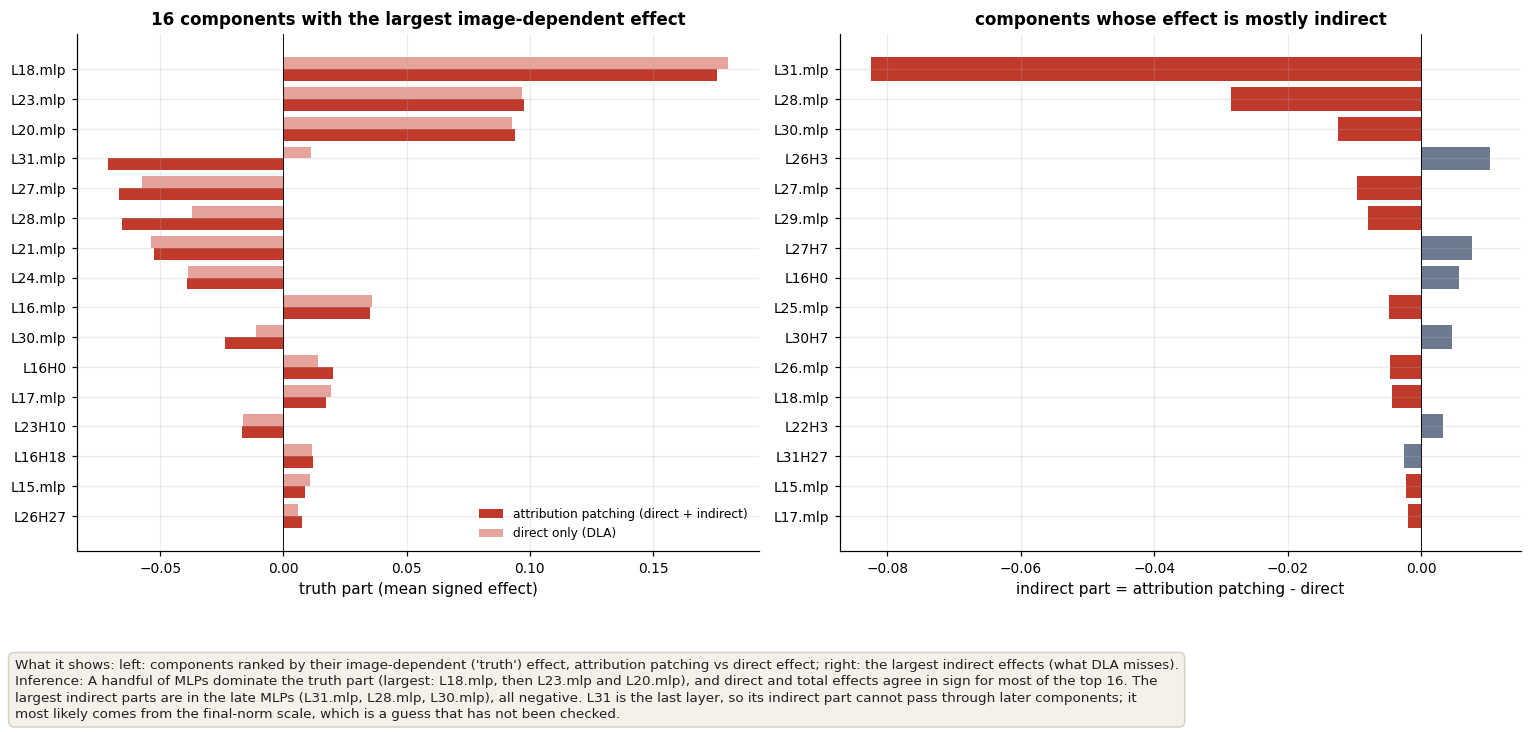

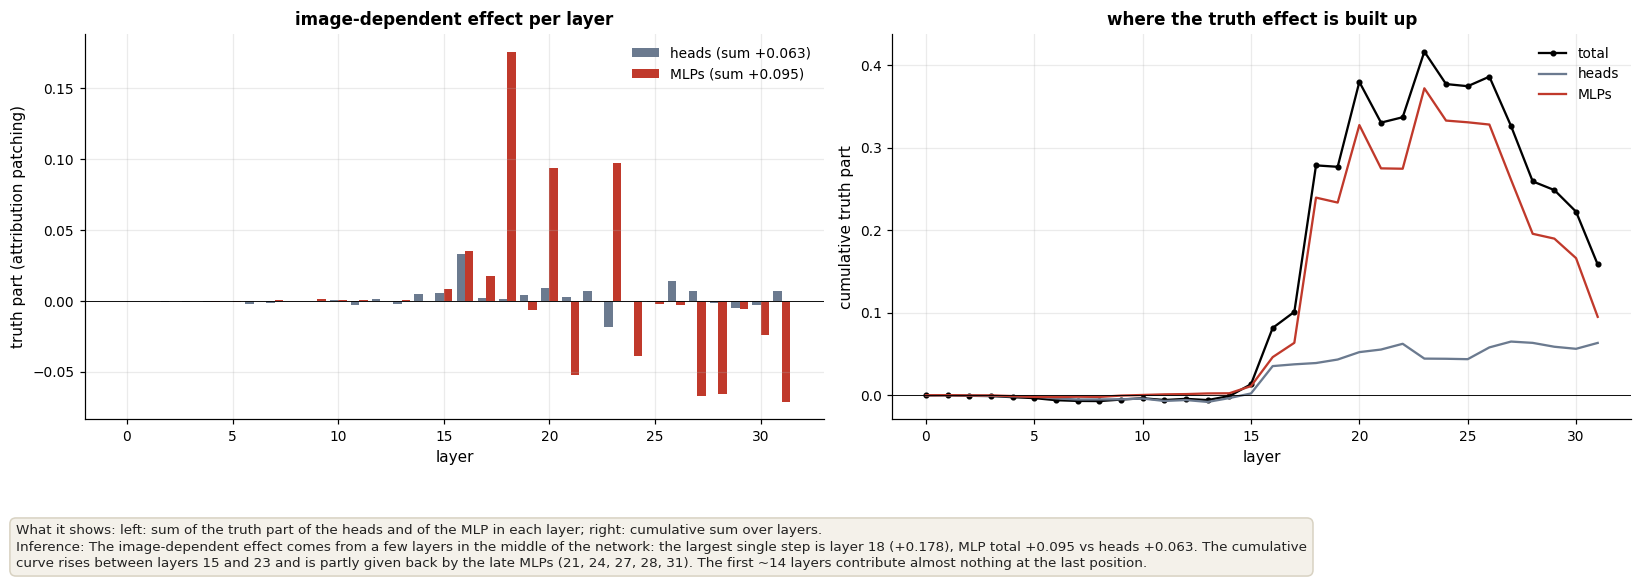

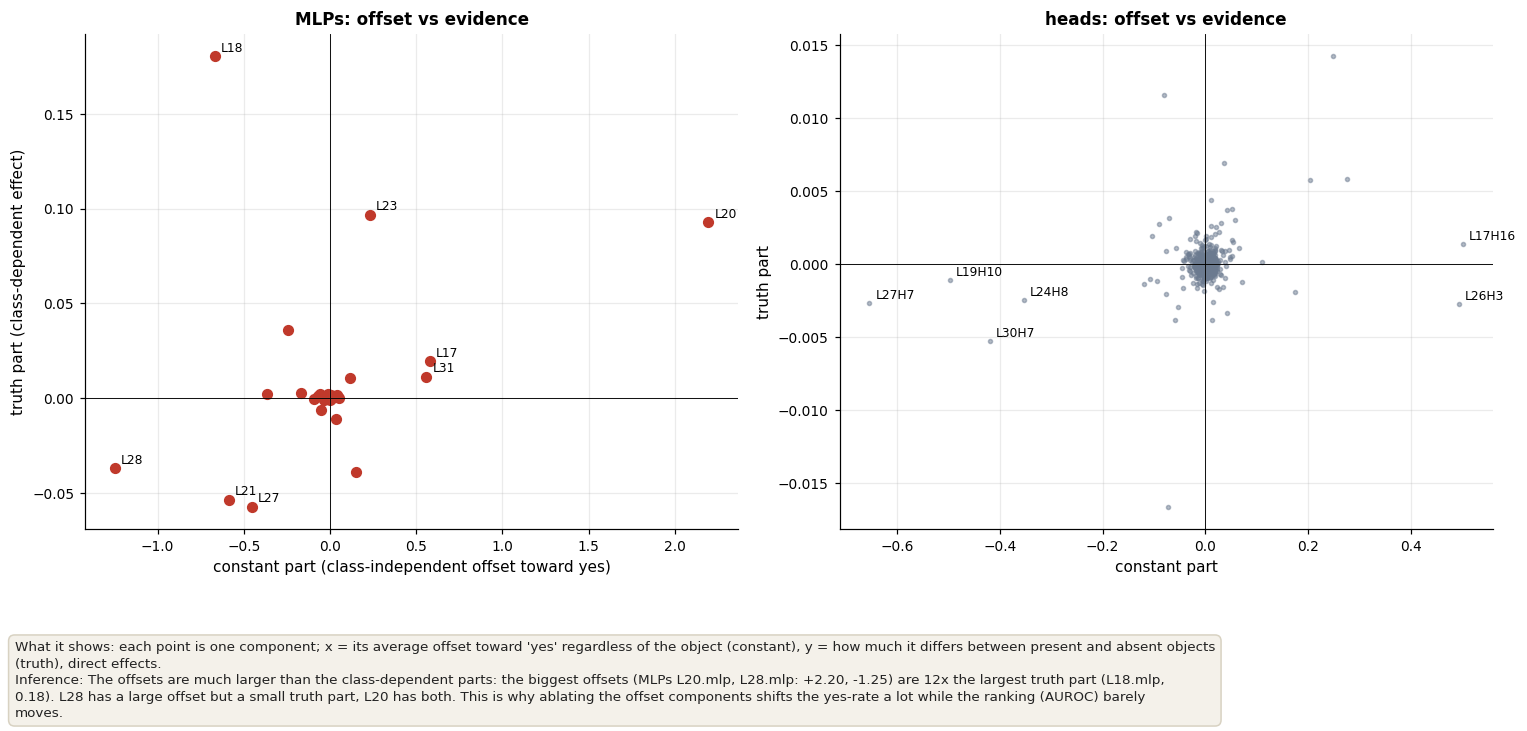

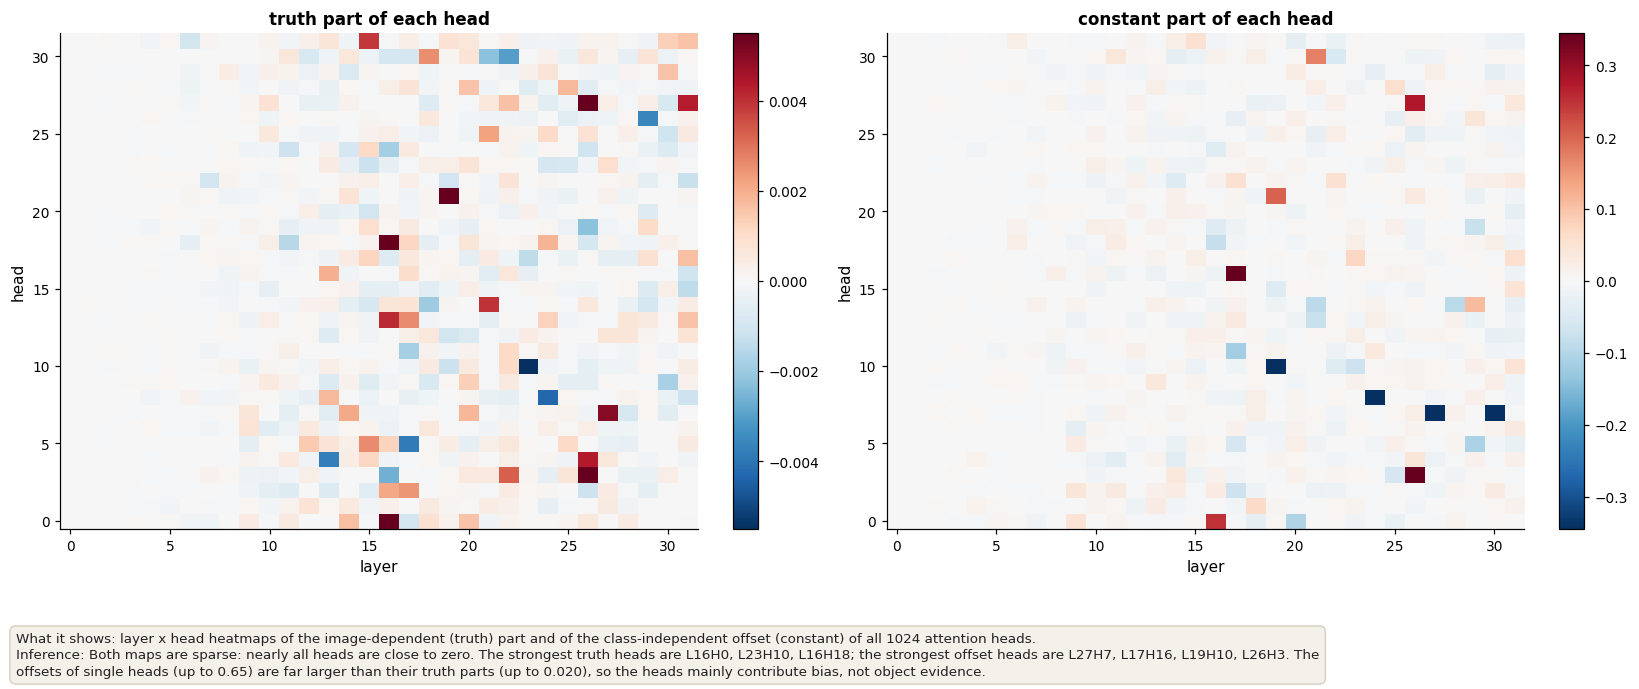

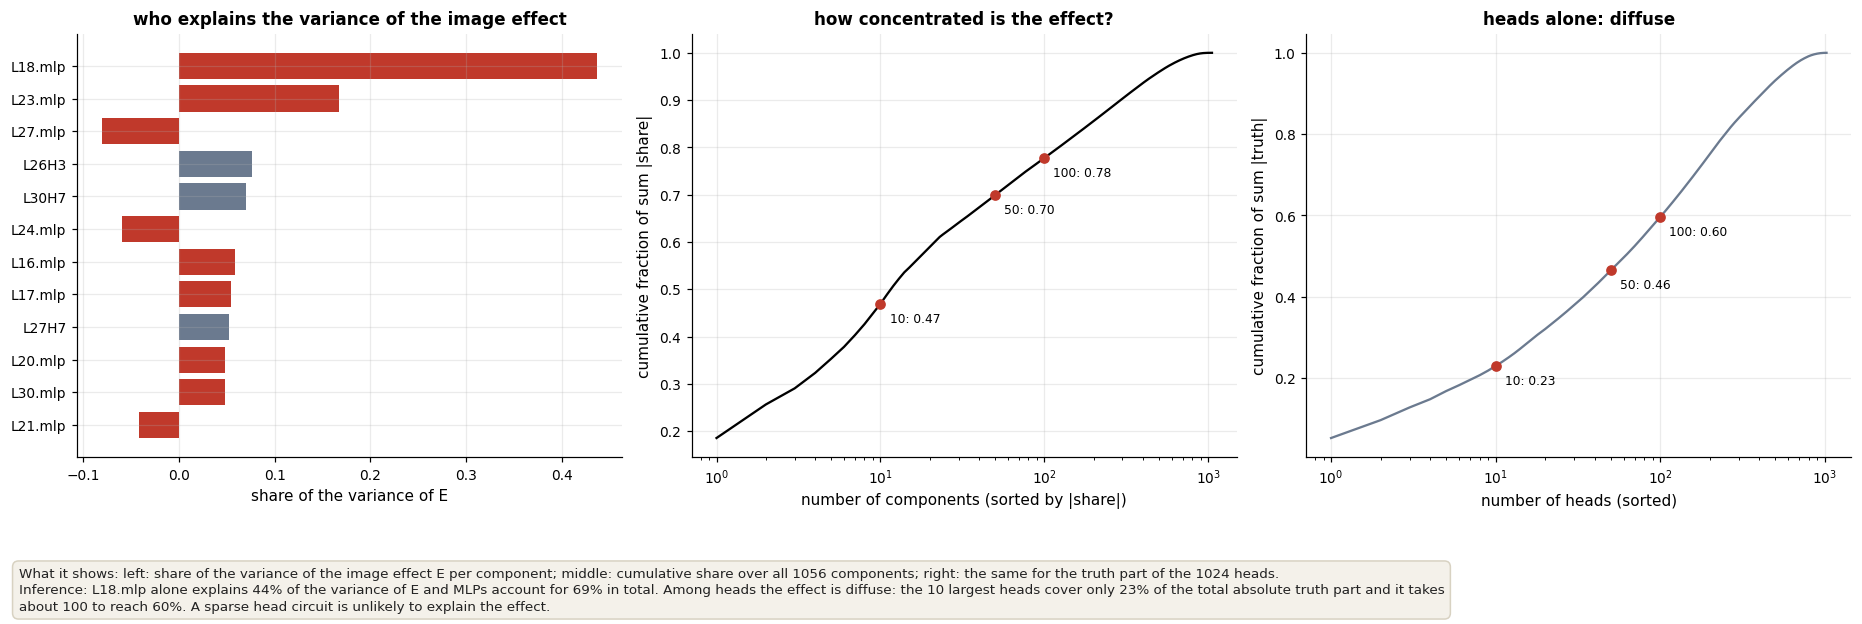

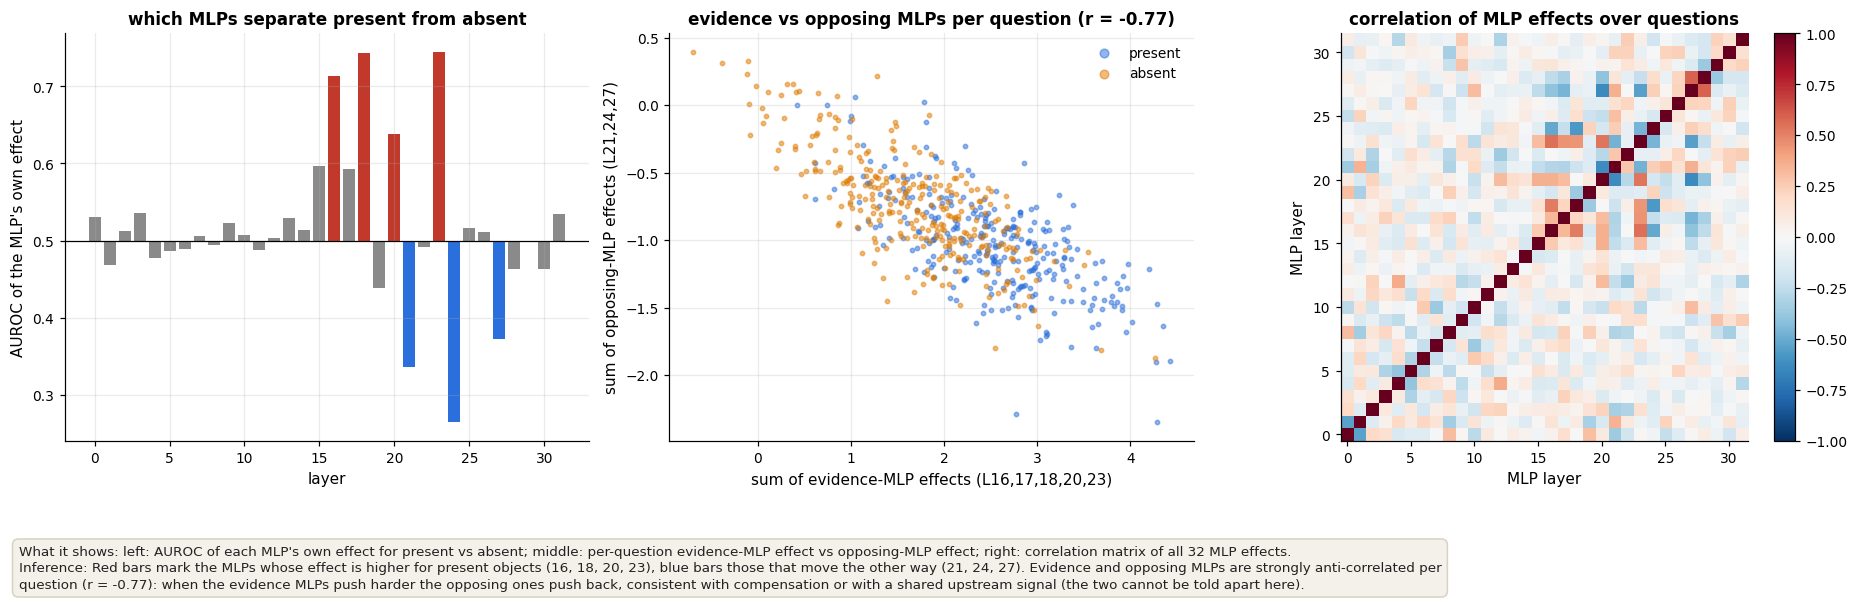

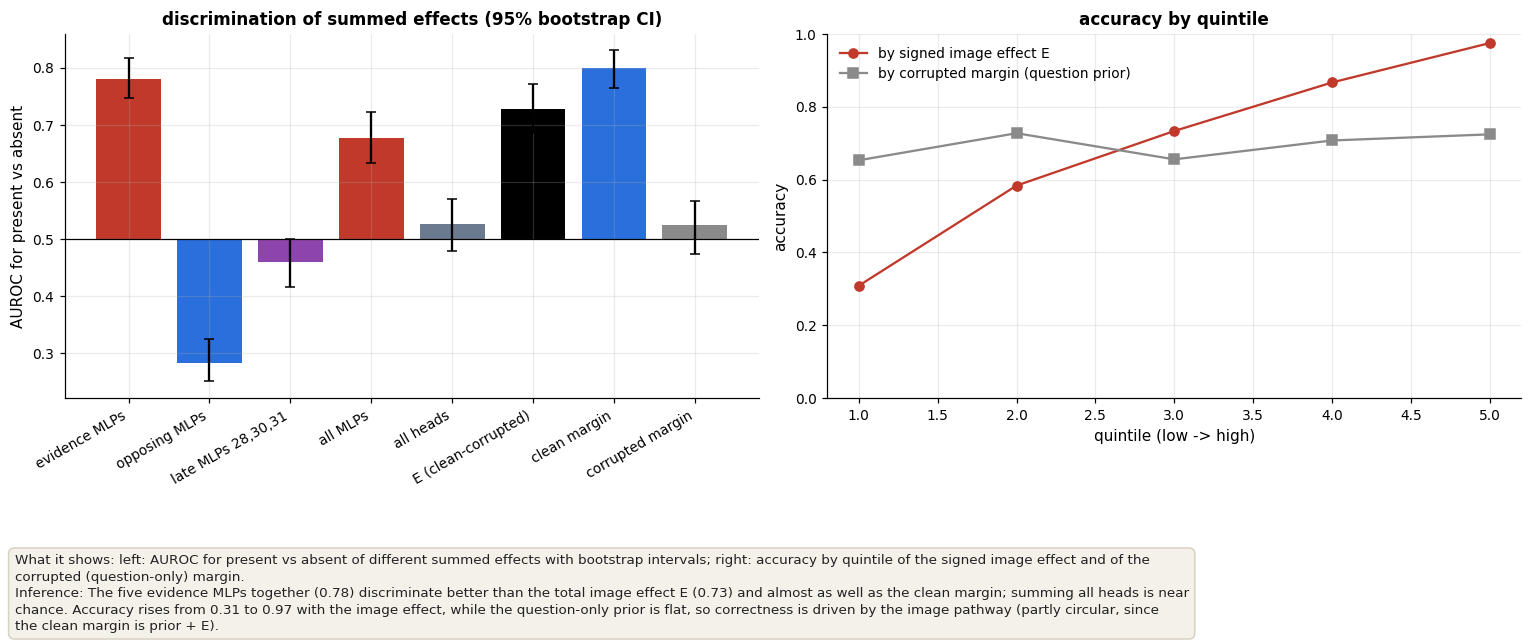

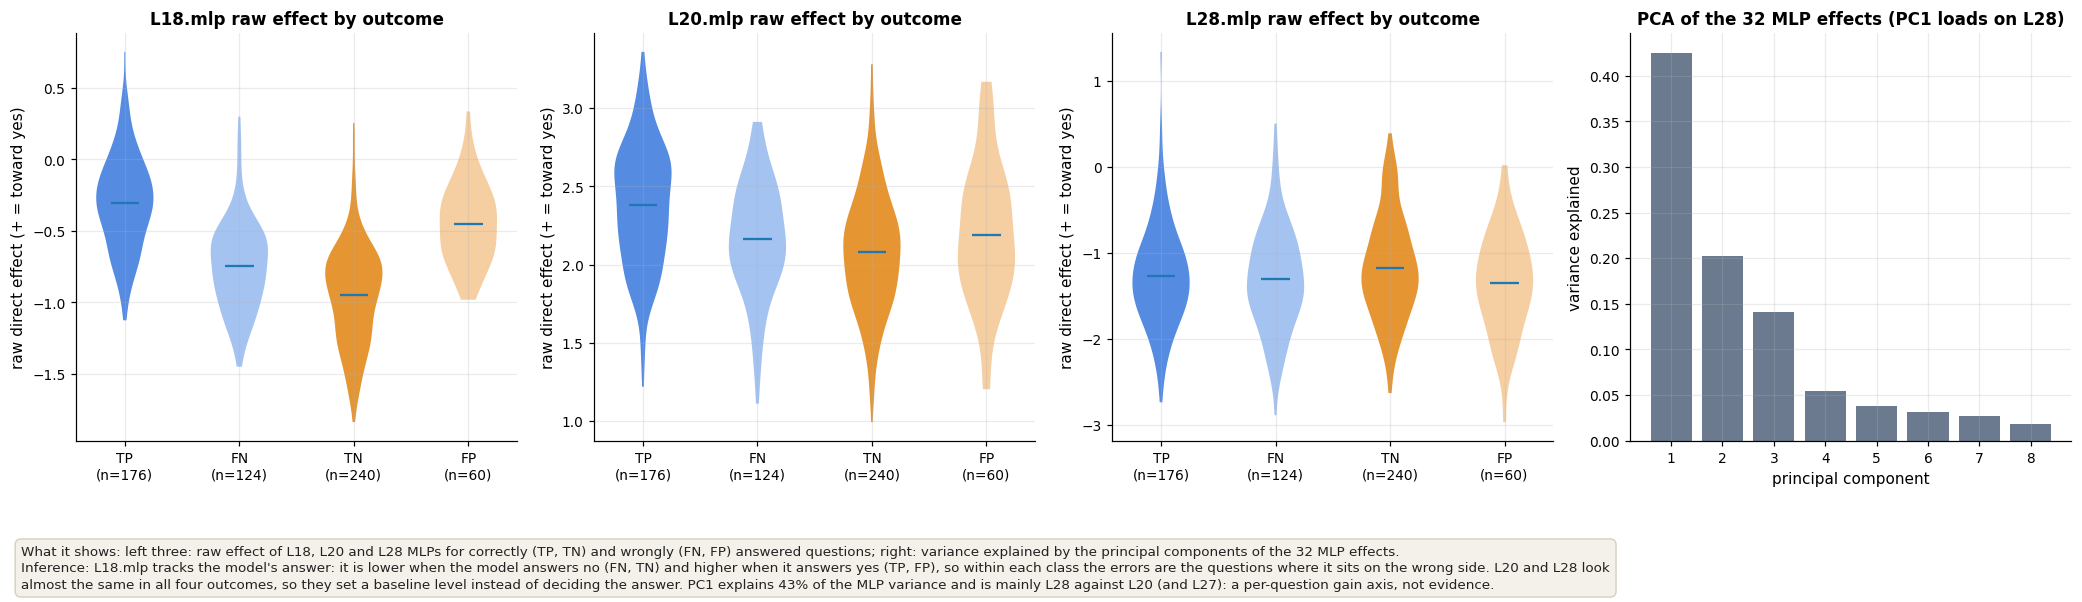

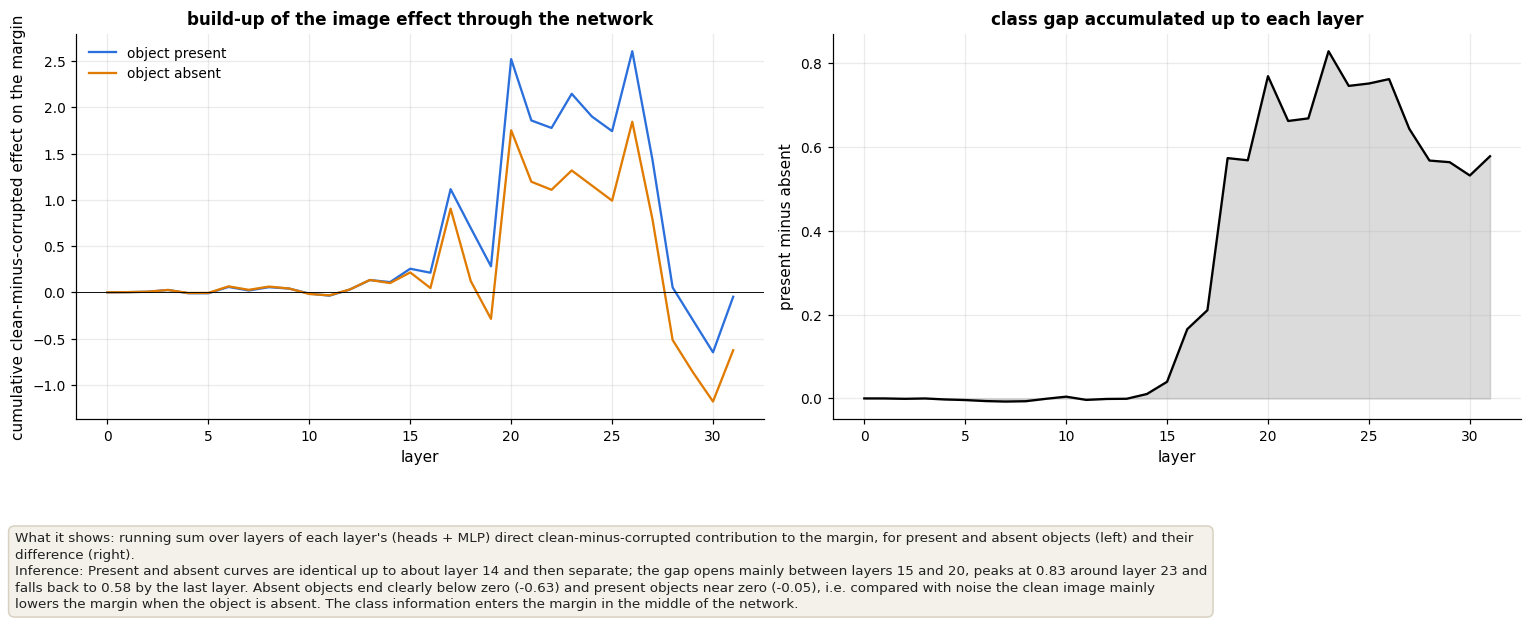

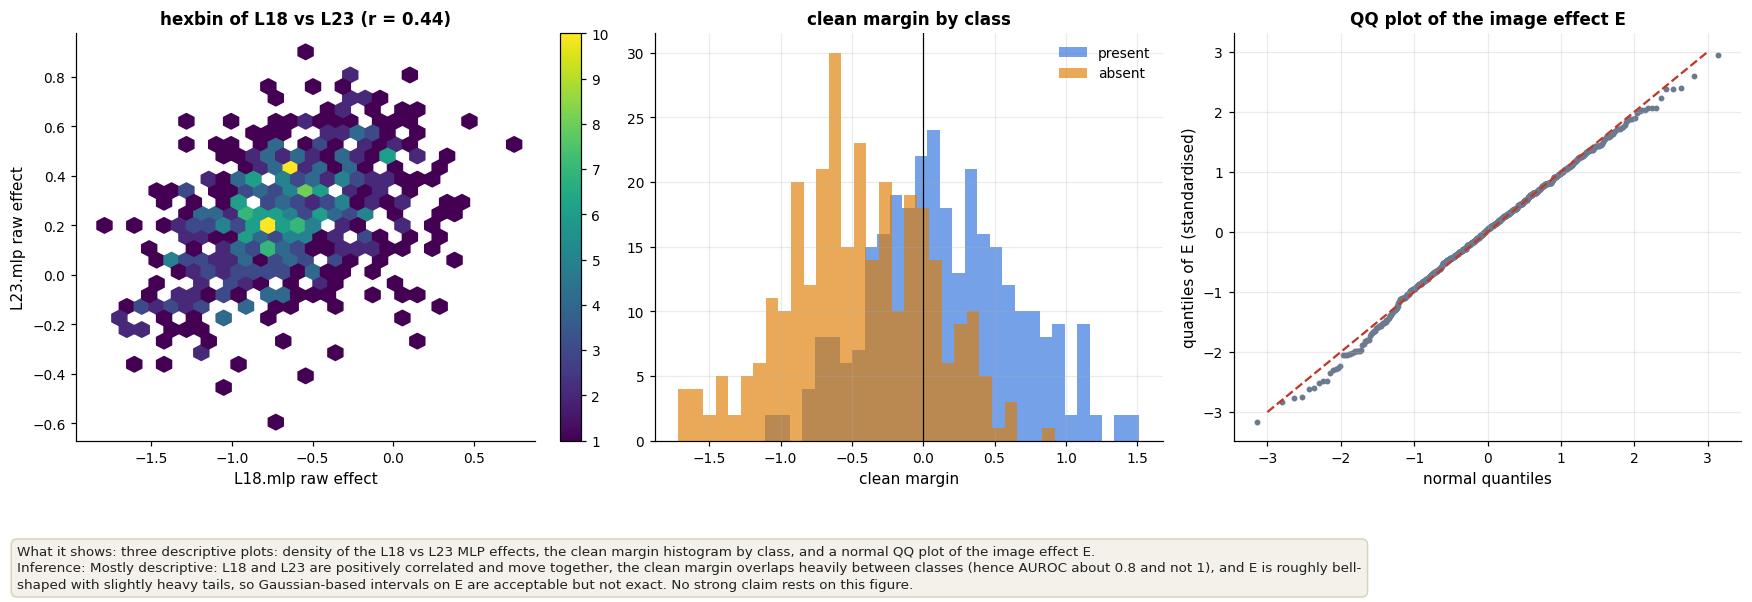

In [4]:
# GRAPHS 5. step 5: attribution patching (clean minus corrupted). Needs atp_results.npz. 'truth part' = mean over questions of (score signed + for present, - for absent)
def _tc():
    P = prep5(); sg = P["sg"][:, None]; y = P["yes"]; T = (P["A"] * sg).mean(0); Td = (P["D"] * sg).mean(0); C = (P["D"][y].mean(0) + P["D"][~y].mean(0)) / 2
    return P, T, Td, C
def _col(n): return COL["mlp"] if n.endswith("mlp") else COL["head"]
@run
def g5_top_components():
    P, T, Td, C = _tc(); n = P["names"]; o = np.argsort(-np.abs(T))[:16][::-1]; fig, ax = plt.subplots(1, 2, figsize=(14, 5.6)); yy = np.arange(len(o))
    ax[0].barh(yy - .2, T[o], .4, color=COL["mlp"], label="attribution patching (direct + indirect)"); ax[0].barh(yy + .2, Td[o], .4, color="#e6a39b", label="direct only (DLA)"); ax[0].set_yticks(yy); ax[0].set_yticklabels(n[o]); ax[0].axvline(0, c="k", lw=.6)
    ax[0].set_xlabel("truth part (mean signed effect)"); ax[0].set_title("16 components with the largest image-dependent effect"); ax[0].legend(fontsize=8)
    ind = T - Td; oo = np.argsort(-np.abs(ind))[:16][::-1]; ax[1].barh(np.arange(16), ind[oo], color=[_col(n[i]) for i in oo]); ax[1].set_yticks(np.arange(16)); ax[1].set_yticklabels(n[oo]); ax[1].axvline(0, c="k", lw=.6)
    ax[1].set_xlabel("indirect part = attribution patching - direct"); ax[1].set_title("components whose effect is mostly indirect")
    finish(fig, "g5_top_components", "left: components ranked by their image-dependent ('truth') effect, attribution patching vs direct effect; right: the largest indirect effects (what DLA misses).",
           f"A handful of MLPs dominate the truth part (largest: {n[o[-1]]}, then {n[o[-2]]} and {n[o[-3]]}), and direct and total effects agree in sign for most of the top 16. The largest indirect parts are in the late MLPs ({n[oo[-1]]}, {n[oo[-2]]}, {n[oo[-3]]}), all negative. L31 is the last layer, so its indirect part cannot pass through later components; it most likely comes from the final-norm scale, which is a guess that has not been checked.")
@run
def g5_layer_profile():
    P, T, Td, C = _tc(); h = T[:1024].reshape(32, 32).sum(1); m = T[1024:]; hd = Td[:1024].reshape(32, 32).sum(1); md = Td[1024:]; x = np.arange(32); fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
    ax[0].bar(x - .2, h, .4, color=COL["head"], label=f"heads (sum {h.sum():+.3f})"); ax[0].bar(x + .2, m, .4, color=COL["mlp"], label=f"MLPs (sum {m.sum():+.3f})"); ax[0].set_xlabel("layer"); ax[0].set_ylabel("truth part (attribution patching)"); ax[0].set_title("image-dependent effect per layer"); ax[0].legend(); ax[0].axhline(0, c="k", lw=.6)
    ax[1].plot(x, np.cumsum(h + m), "o-", c="k", ms=3, label="total"); ax[1].plot(x, np.cumsum(h), c=COL["head"], label="heads"); ax[1].plot(x, np.cumsum(m), c=COL["mlp"], label="MLPs"); ax[1].set_xlabel("layer"); ax[1].set_ylabel("cumulative truth part"); ax[1].set_title("where the truth effect is built up"); ax[1].legend(); ax[1].axhline(0, c="k", lw=.6)
    finish(fig, "g5_layer_profile", "left: sum of the truth part of the heads and of the MLP in each layer; right: cumulative sum over layers.",
           f"The image-dependent effect comes from a few layers in the middle of the network: the largest single step is layer {int(np.argmax(h + m))} ({(h + m).max():+.3f}), MLP total {m.sum():+.3f} vs heads {h.sum():+.3f}. The cumulative curve rises between layers 15 and 23 and is partly given back by the late MLPs (21, 24, 27, 28, 31). The first ~14 layers contribute almost nothing at the last position.")
@run
def g5_constant_vs_truth():
    P, T, Td, C = _tc(); n = P["names"]; fig, ax = plt.subplots(1, 2, figsize=(14, 5.4)); ii = np.arange(1024, 1056)
    ax[0].scatter(C[ii], Td[ii], c=COL["mlp"], s=40)
    for i in ii:
        if abs(C[i]) > .4 or abs(Td[i]) > .06: ax[0].annotate(n[i].replace(".mlp", ""), (C[i], Td[i]), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax[0].axhline(0, c="k", lw=.6); ax[0].axvline(0, c="k", lw=.6); ax[0].set_xlabel("constant part (class-independent offset toward yes)"); ax[0].set_ylabel("truth part (class-dependent effect)"); ax[0].set_title("MLPs: offset vs evidence")
    jj = np.arange(1024); ax[1].scatter(C[jj], Td[jj], c=COL["head"], s=7, alpha=.5)
    for i in jj[np.argsort(-np.abs(C[jj]))[:6]]: ax[1].annotate(n[i], (C[i], Td[i]), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax[1].axhline(0, c="k", lw=.6); ax[1].axvline(0, c="k", lw=.6); ax[1].set_xlabel("constant part"); ax[1].set_ylabel("truth part"); ax[1].set_title("heads: offset vs evidence")
    finish(fig, "g5_constant_vs_truth", "each point is one component; x = its average offset toward 'yes' regardless of the object (constant), y = how much it differs between present and absent objects (truth), direct effects.",
           f"The offsets are much larger than the class-dependent parts: the biggest offsets (MLPs {', '.join(n[1024 + i] for i in np.argsort(-np.abs(C[1024:]))[:2])}: {', '.join(f'{C[1024 + i]:+.2f}' for i in np.argsort(-np.abs(C[1024:]))[:2])}) are {np.abs(C[1024:]).max() / np.abs(Td[1024:]).max():.0f}x the largest truth part ({n[1024 + int(np.argmax(np.abs(Td[1024:])))]}, {np.abs(Td[1024:]).max():.2f}). L28 has a large offset but a small truth part, L20 has both. This is why ablating the offset components shifts the yes-rate a lot while the ranking (AUROC) barely moves.")
@run
def g5_head_heatmaps():
    P, T, Td, C = _tc(); n = P["names"]; fig, ax = plt.subplots(1, 2, figsize=(15, 5.4))
    for a, M, ttl in [(ax[0], T[:1024].reshape(32, 32), "truth part of each head"), (ax[1], C[:1024].reshape(32, 32), "constant part of each head")]:
        v = np.percentile(np.abs(M), 99.5); im = a.imshow(M.T, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto", origin="lower"); a.set_xlabel("layer"); a.set_ylabel("head"); a.set_title(ttl); a.grid(False); plt.colorbar(im, ax=a, fraction=.04)
    finish(fig, "g5_head_heatmaps", "layer x head heatmaps of the image-dependent (truth) part and of the class-independent offset (constant) of all 1024 attention heads.",
           f"Both maps are sparse: nearly all heads are close to zero. The strongest truth heads are {', '.join(n[i] for i in np.argsort(-np.abs(T[:1024]))[:3])}; the strongest offset heads are {', '.join(n[i] for i in np.argsort(-np.abs(C[:1024]))[:4])}. The offsets of single heads (up to {np.abs(C[:1024]).max():.2f}) are far larger than their truth parts (up to {np.abs(T[:1024]).max():.3f}), so the heads mainly contribute bias, not object evidence.")
@run
def g5_variance_and_diffuseness():
    P, T, Td, C = _tc(); n = P["names"]; D = P["D"]; E = P["E"]; vs = np.array([np.cov(D[:, i], E)[0, 1] for i in range(D.shape[1])]) / E.var(ddof=1); o = np.argsort(-np.abs(vs))[:12][::-1]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); ax[0].barh(range(12), vs[o], color=[_col(n[i]) for i in o]); ax[0].set_yticks(range(12)); ax[0].set_yticklabels(n[o]); ax[0].set_xlabel("share of the variance of E"); ax[0].set_title("who explains the variance of the image effect")
    cs = np.cumsum(np.sort(np.abs(vs))[::-1]) / np.abs(vs).sum(); ax[1].plot(np.arange(1, len(cs) + 1), cs, c="k"); ax[1].set_xscale("log"); ax[1].set_xlabel("number of components (sorted by |share|)"); ax[1].set_ylabel("cumulative fraction of sum |share|"); ax[1].set_title("how concentrated is the effect?")
    for k in (10, 50, 100): ax[1].scatter([k], [cs[k - 1]], c=COL["bad"], zorder=3); ax[1].annotate(f"{k}: {cs[k - 1]:.2f}", (k, cs[k - 1]), xytext=(6, -12), textcoords="offset points", fontsize=8)
    hh = np.abs(T[:1024]); hs = np.cumsum(np.sort(hh)[::-1]) / hh.sum(); ax[2].plot(np.arange(1, 1025), hs, c=COL["head"]); ax[2].set_xscale("log"); ax[2].set_xlabel("number of heads (sorted)"); ax[2].set_ylabel("cumulative fraction of sum |truth|"); ax[2].set_title("heads alone: diffuse")
    for k in (10, 50, 100): ax[2].scatter([k], [hs[k - 1]], c=COL["bad"], zorder=3); ax[2].annotate(f"{k}: {hs[k - 1]:.2f}", (k, hs[k - 1]), xytext=(6, -12), textcoords="offset points", fontsize=8)
    finish(fig, "g5_variance_and_diffuseness", "left: share of the variance of the image effect E per component; middle: cumulative share over all 1056 components; right: the same for the truth part of the 1024 heads.",
           f"{n[o[-1]]} alone explains {vs[o[-1]]:.0%} of the variance of E and MLPs account for {vs[1024:].sum():.0%} in total. Among heads the effect is diffuse: the 10 largest heads cover only {hs[9]:.0%} of the total absolute truth part and it takes about 100 to reach {hs[99]:.0%}. A sparse head circuit is unlikely to explain the effect.")
@run
def g5_mlp_auroc_and_coupling():
    P, T, Td, C = _tc(); D = P["D"]; y = P["yes"]; al = np.array([auc(D[:, 1024 + l], y) for l in range(32)]); fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    ax[0].bar(range(32), al - .5, bottom=.5, color=[COL["ev"] if a > .62 else (COL["op"] if a < .38 else COL["grey"]) for a in al]); ax[0].axhline(.5, c="k", lw=.8); ax[0].set_xlabel("layer"); ax[0].set_ylabel("AUROC of the MLP's own effect"); ax[0].set_title("which MLPs separate present from absent")
    ev, op = D[:, [1024 + l for l in EV_L]].sum(1), D[:, [1024 + l for l in OP_L]].sum(1); r = np.corrcoef(ev, op)[0, 1]
    ax[1].scatter(ev[y], op[y], s=8, alpha=.5, c=COL["pres"], label="present"); ax[1].scatter(ev[~y], op[~y], s=8, alpha=.5, c=COL["absn"], label="absent"); ax[1].set_xlabel("sum of evidence-MLP effects (L16,17,18,20,23)"); ax[1].set_ylabel("sum of opposing-MLP effects (L21,24,27)"); ax[1].set_title(f"evidence vs opposing MLPs per question (r = {r:.2f})"); ax[1].legend(markerscale=2)
    Cm = np.corrcoef(D[:, 1024:].T); im = ax[2].imshow(Cm, cmap="RdBu_r", vmin=-1, vmax=1, origin="lower"); ax[2].set_xlabel("MLP layer"); ax[2].set_ylabel("MLP layer"); ax[2].set_title("correlation of MLP effects over questions"); ax[2].grid(False); plt.colorbar(im, ax=ax[2], fraction=.046)
    finish(fig, "g5_mlp_auroc_and_coupling", "left: AUROC of each MLP's own effect for present vs absent; middle: per-question evidence-MLP effect vs opposing-MLP effect; right: correlation matrix of all 32 MLP effects.",
           f"Red bars mark the MLPs whose effect is higher for present objects ({', '.join(str(l) for l in range(32) if al[l] > .62)}), blue bars those that move the other way ({', '.join(str(l) for l in range(32) if al[l] < .38)}). Evidence and opposing MLPs are strongly anti-correlated per question (r = {r:.2f}): when the evidence MLPs push harder the opposing ones push back, consistent with compensation or with a shared upstream signal (the two cannot be told apart here).")
@run
def g5_group_auroc():
    P, T, Td, C = _tc(); D = P["D"]; y = P["yes"]; mm = lambda L: D[:, [1024 + l for l in L]].sum(1); rng = np.random.default_rng(0); iy, ino = np.where(y)[0], np.where(~y)[0]
    items = [("evidence MLPs", mm(EV_L)), ("opposing MLPs", mm(OP_L)), ("late MLPs 28,30,31", mm(BR_L)), ("all MLPs", D[:, 1024:].sum(1)), ("all heads", D[:, :1024].sum(1)), ("E (clean-corrupted)", P["E"]), ("clean margin", P["ldc"]), ("corrupted margin", P["ldn"])]
    pts, lo, hi = [], [], []
    for nme, v in items:
        bs = [auc(v[i], y[i]) for i in (np.concatenate([rng.choice(iy, len(iy)), rng.choice(ino, len(ino))]) for _ in range(300))]; pts.append(auc(v, y)); lo.append(np.percentile(bs, 2.5)); hi.append(np.percentile(bs, 97.5))
    pts, lo, hi = map(np.array, (pts, lo, hi)); fig, ax = plt.subplots(1, 2, figsize=(14, 4.6)); cols = [COL["ev"], COL["op"], COL["br"], COL["mlp"], COL["head"], "k", COL["pres"], COL["grey"]]
    ax[0].bar(range(len(items)), pts - .5, bottom=.5, yerr=[pts - lo, hi - pts], color=cols, capsize=3); ax[0].axhline(.5, c="k", lw=.8); ax[0].set_xticks(range(len(items))); ax[0].set_xticklabels([i[0] for i in items], rotation=30, ha="right"); ax[0].set_ylabel("AUROC for present vs absent"); ax[0].set_title("discrimination of summed effects (95% bootstrap CI)")
    y5 = P["sg"] * P["E"]; q = pd.qcut(y5, 5, labels=False); q2 = pd.qcut(P["ldn"], 5, labels=False); corr = (P["out"] == "TP") | (P["out"] == "TN")
    ax[1].plot(range(1, 6), [corr[q == k].mean() for k in range(5)], "o-", c=COL["ev"], label="by signed image effect E"); ax[1].plot(range(1, 6), [corr[q2 == k].mean() for k in range(5)], "s-", c=COL["grey"], label="by corrupted margin (question prior)"); ax[1].set_xlabel("quintile (low -> high)"); ax[1].set_ylabel("accuracy"); ax[1].set_title("accuracy by quintile"); ax[1].legend(); ax[1].set_ylim(0, 1)
    finish(fig, "g5_group_auroc", "left: AUROC for present vs absent of different summed effects with bootstrap intervals; right: accuracy by quintile of the signed image effect and of the corrupted (question-only) margin.",
           f"The five evidence MLPs together ({pts[0]:.2f}) discriminate better than the total image effect E ({pts[5]:.2f}) and almost as well as the clean margin; summing all heads is near chance. Accuracy rises from {corr[q == 0].mean():.2f} to {corr[q == 4].mean():.2f} with the image effect, while the question-only prior is flat, so correctness is driven by the image pathway (partly circular, since the clean margin is prior + E).")
@run
def g5_outcomes_and_pca():
    P, T, Td, C = _tc(); D = P["D"]; out = P["out"]; fig, ax = plt.subplots(1, 4, figsize=(19, 4.6)); order = ["TP", "FN", "TN", "FP"]; cc = [COL["pres"], "#8fb4ee", COL["absn"], "#f3c28b"]
    for a, l in zip(ax[:3], (18, 20, 28)):
        data = [D[out == o, 1024 + l] for o in order]; vp = a.violinplot(data, showmeans=True, showextrema=False)
        for b_, c in zip(vp["bodies"], cc): b_.set_facecolor(c); b_.set_alpha(.8)
        a.set_xticks(range(1, 5)); a.set_xticklabels([f"{o}\n(n={int((out == o).sum())})" for o in order]); a.set_title(f"L{l}.mlp raw effect by outcome"); a.set_ylabel("raw direct effect (+ = toward yes)")
    M = D[:, 1024:]; Mc = M - M.mean(0); U, s, Vt = np.linalg.svd(Mc, full_matrices=False); ve = s ** 2 / (s ** 2).sum()
    ax[3].bar(range(1, 9), ve[:8], color=COL["head"]); ax[3].set_xlabel("principal component"); ax[3].set_ylabel("variance explained"); ax[3].set_title(f"PCA of the 32 MLP effects (PC1 loads on L{int(np.argmax(np.abs(Vt[0])))})")
    finish(fig, "g5_outcomes_and_pca", "left three: raw effect of L18, L20 and L28 MLPs for correctly (TP, TN) and wrongly (FN, FP) answered questions; right: variance explained by the principal components of the 32 MLP effects.",
           f"L18.mlp tracks the model's answer: it is lower when the model answers no (FN, TN) and higher when it answers yes (TP, FP), so within each class the errors are the questions where it sits on the wrong side. L20 and L28 look almost the same in all four outcomes, so they set a baseline level instead of deciding the answer. PC1 explains {ve[0]:.0%} of the MLP variance and is mainly L28 against L20 (and L27): a per-question gain axis, not evidence.")
@run
def g5_logit_build_up():
    P, T, Td, C = _tc(); D = P["D"]; y = P["yes"]; lay = D[:, :1024].reshape(-1, 32, 32).sum(2) + D[:, 1024:]; cp, ca = np.cumsum(lay[y].mean(0)), np.cumsum(lay[~y].mean(0)); x = np.arange(32); fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    ax[0].plot(x, cp, c=COL["pres"], label="object present"); ax[0].plot(x, ca, c=COL["absn"], label="object absent"); ax[0].set_xlabel("layer"); ax[0].set_ylabel("cumulative clean-minus-corrupted effect on the margin"); ax[0].set_title("build-up of the image effect through the network"); ax[0].legend(); ax[0].axhline(0, c="k", lw=.6)
    ax[1].plot(x, cp - ca, c="k"); ax[1].fill_between(x, 0, cp - ca, color=COL["grey"], alpha=.3); ax[1].set_xlabel("layer"); ax[1].set_ylabel("present minus absent"); ax[1].set_title("class gap accumulated up to each layer")
    finish(fig, "g5_logit_build_up", "running sum over layers of each layer's (heads + MLP) direct clean-minus-corrupted contribution to the margin, for present and absent objects (left) and their difference (right).",
           f"Present and absent curves are identical up to about layer 14 and then separate; the gap opens mainly between layers 15 and 20, peaks at {(cp - ca).max():.2f} around layer {int(np.argmax(cp - ca))} and falls back to {(cp - ca)[-1]:.2f} by the last layer. Absent objects end clearly below zero ({ca[-1]:+.2f}) and present objects near zero ({cp[-1]:+.2f}), i.e. compared with noise the clean image mainly lowers the margin when the object is absent. The class information enters the margin in the middle of the network.")
@run
def g5_random_extras():
    P, T, Td, C = _tc(); D = P["D"]; y = P["yes"]; fig, ax = plt.subplots(1, 3, figsize=(16, 4.6)); a, b = D[:, 1024 + 18], D[:, 1024 + 23]
    hb = ax[0].hexbin(a, b, gridsize=28, cmap="viridis", mincnt=1); ax[0].set_xlabel("L18.mlp raw effect"); ax[0].set_ylabel("L23.mlp raw effect"); ax[0].set_title(f"hexbin of L18 vs L23 (r = {np.corrcoef(a, b)[0, 1]:.2f})"); ax[0].grid(False); plt.colorbar(hb, ax=ax[0], fraction=.046)
    ax[1].hist(P["ldc"][y], 30, alpha=.65, color=COL["pres"], label="present"); ax[1].hist(P["ldc"][~y], 30, alpha=.65, color=COL["absn"], label="absent"); ax[1].axvline(0, c="k", lw=.8); ax[1].set_xlabel("clean margin"); ax[1].set_title("clean margin by class"); ax[1].legend()
    from scipy import stats; z = np.sort((P["E"] - P["E"].mean()) / P["E"].std()); q = stats.norm.ppf((np.arange(1, len(z) + 1) - .5) / len(z)); ax[2].scatter(q, z, s=8, c=COL["head"]); ax[2].plot([-3, 3], [-3, 3], c=COL["bad"], ls="--"); ax[2].set_xlabel("normal quantiles"); ax[2].set_ylabel("quantiles of E (standardised)"); ax[2].set_title("QQ plot of the image effect E")
    finish(fig, "g5_random_extras", "three descriptive plots: density of the L18 vs L23 MLP effects, the clean margin histogram by class, and a normal QQ plot of the image effect E.",
           "Mostly descriptive: L18 and L23 are positively correlated and move together, the clean margin overlaps heavily between classes (hence AUROC about 0.8 and not 1), and E is roughly bell-shaped with slightly heavy tails, so Gaussian-based intervals on E are acceptable but not exact. No strong claim rests on this figure.")


## Step 6 and 6x: mean-ablation and layer localisation (needs `meanablation_table.csv`, `meanablation_results.npz`, `mlp_localisation_table.csv`, `mlp_localisation.npz`)

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/meanablation_table.csv


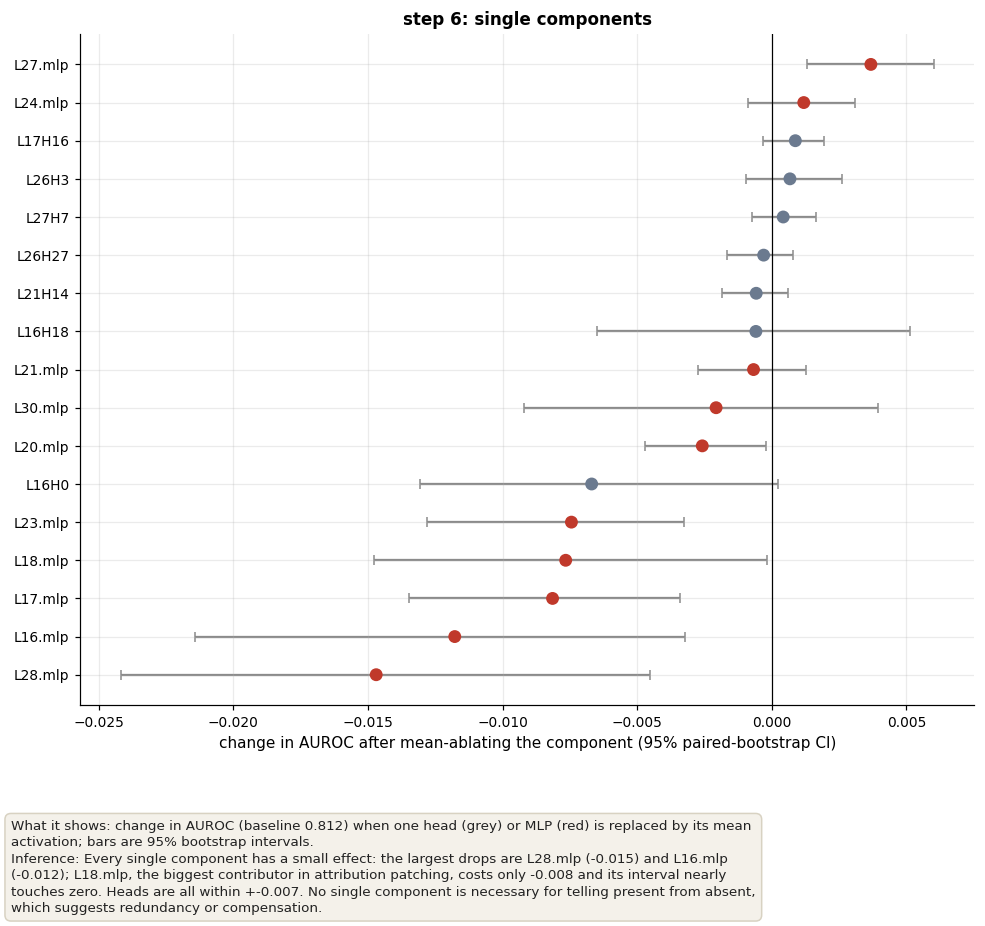

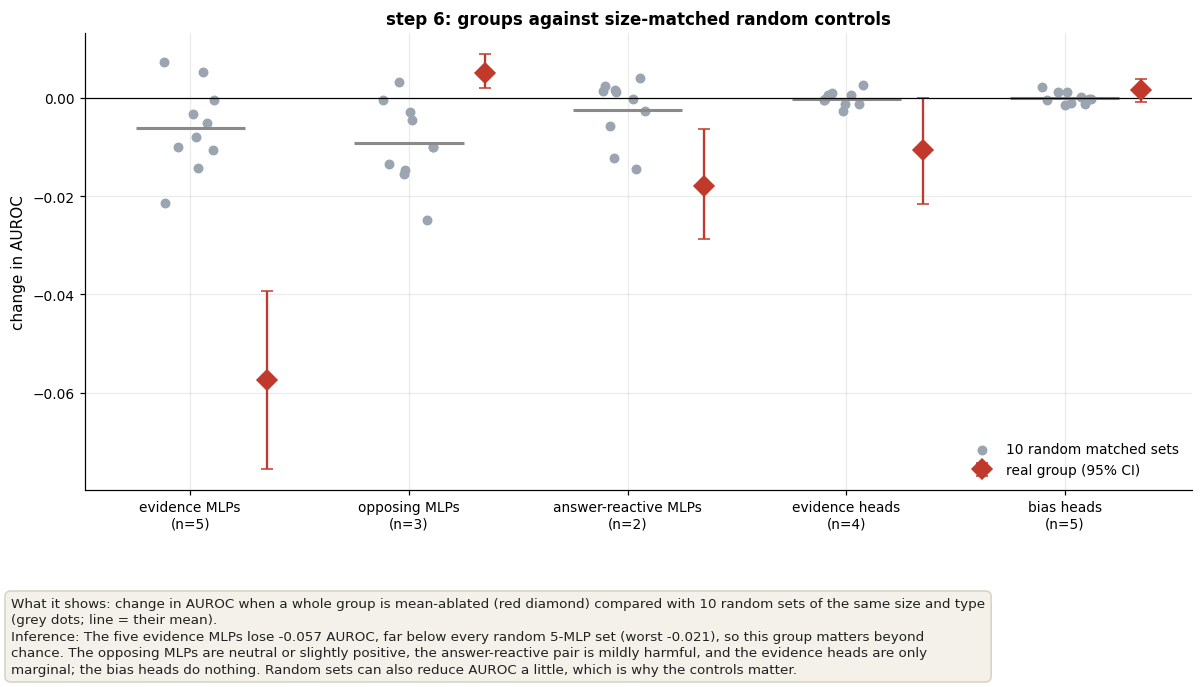

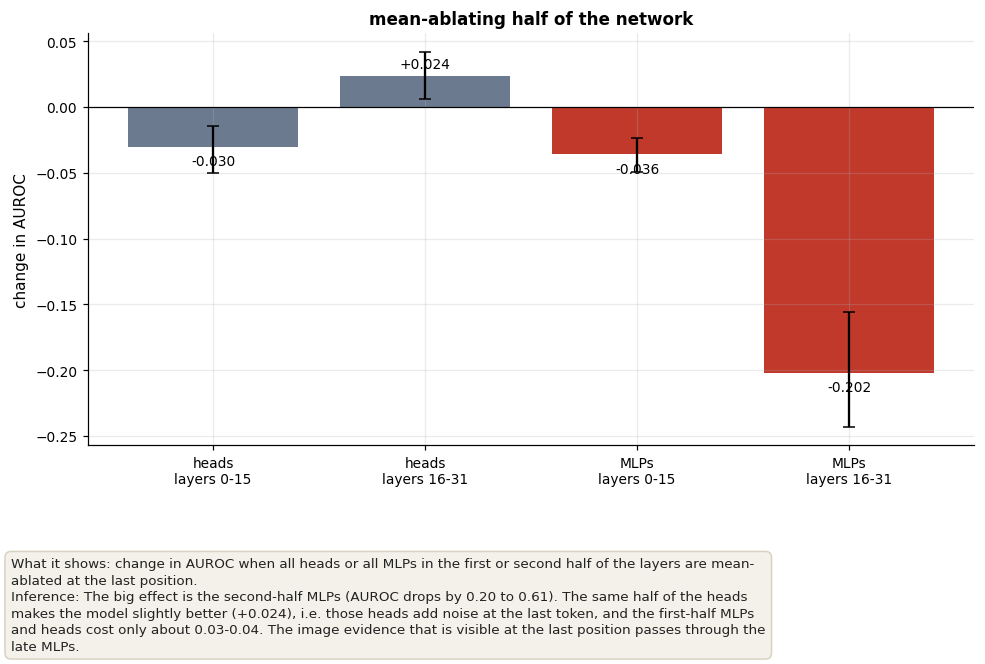

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/meanablation_results.npz


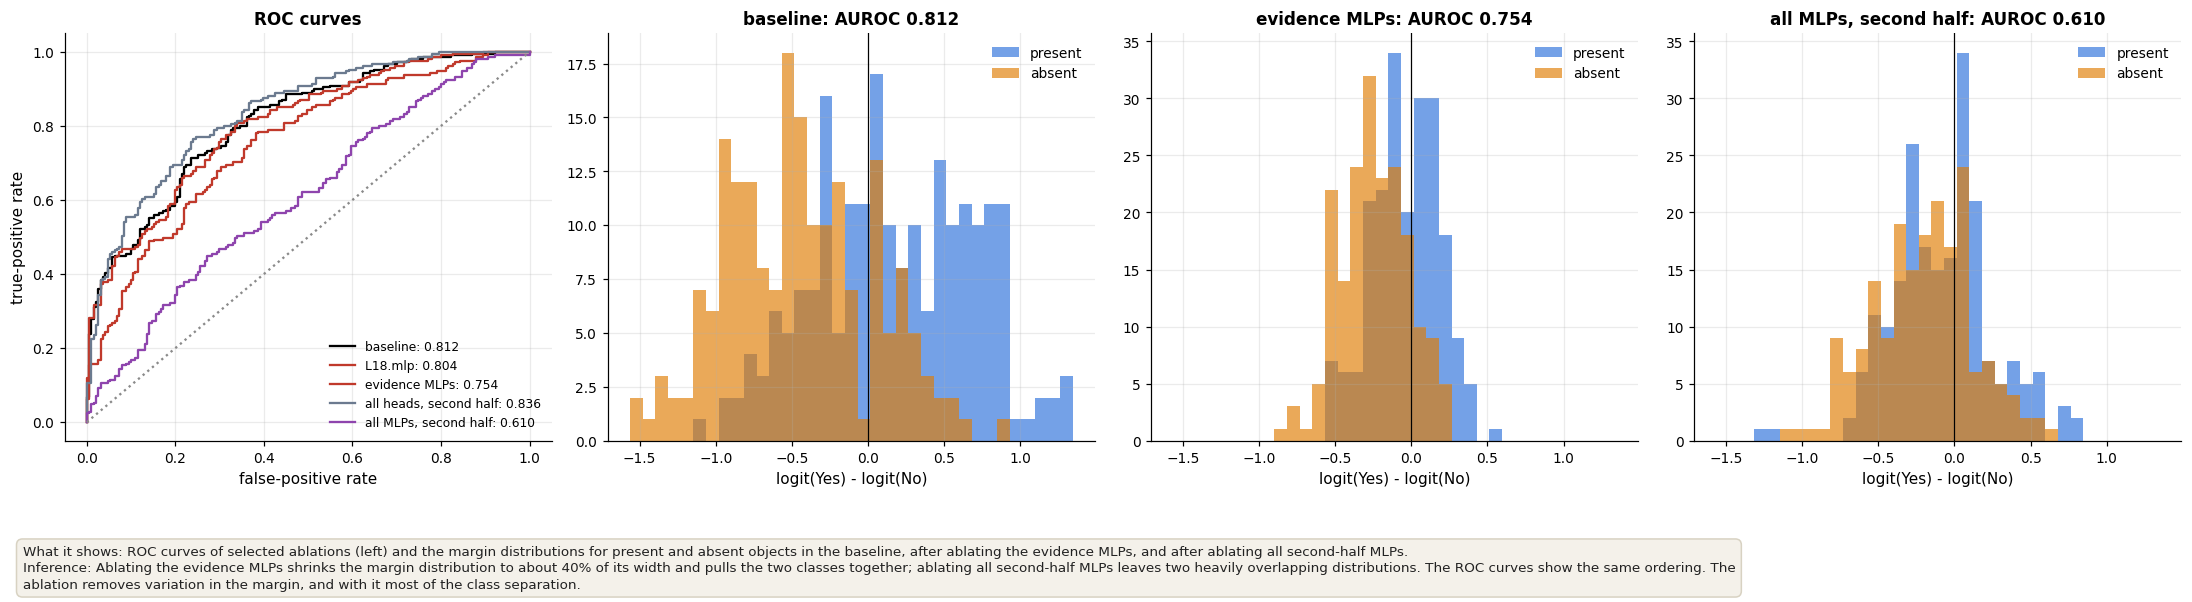

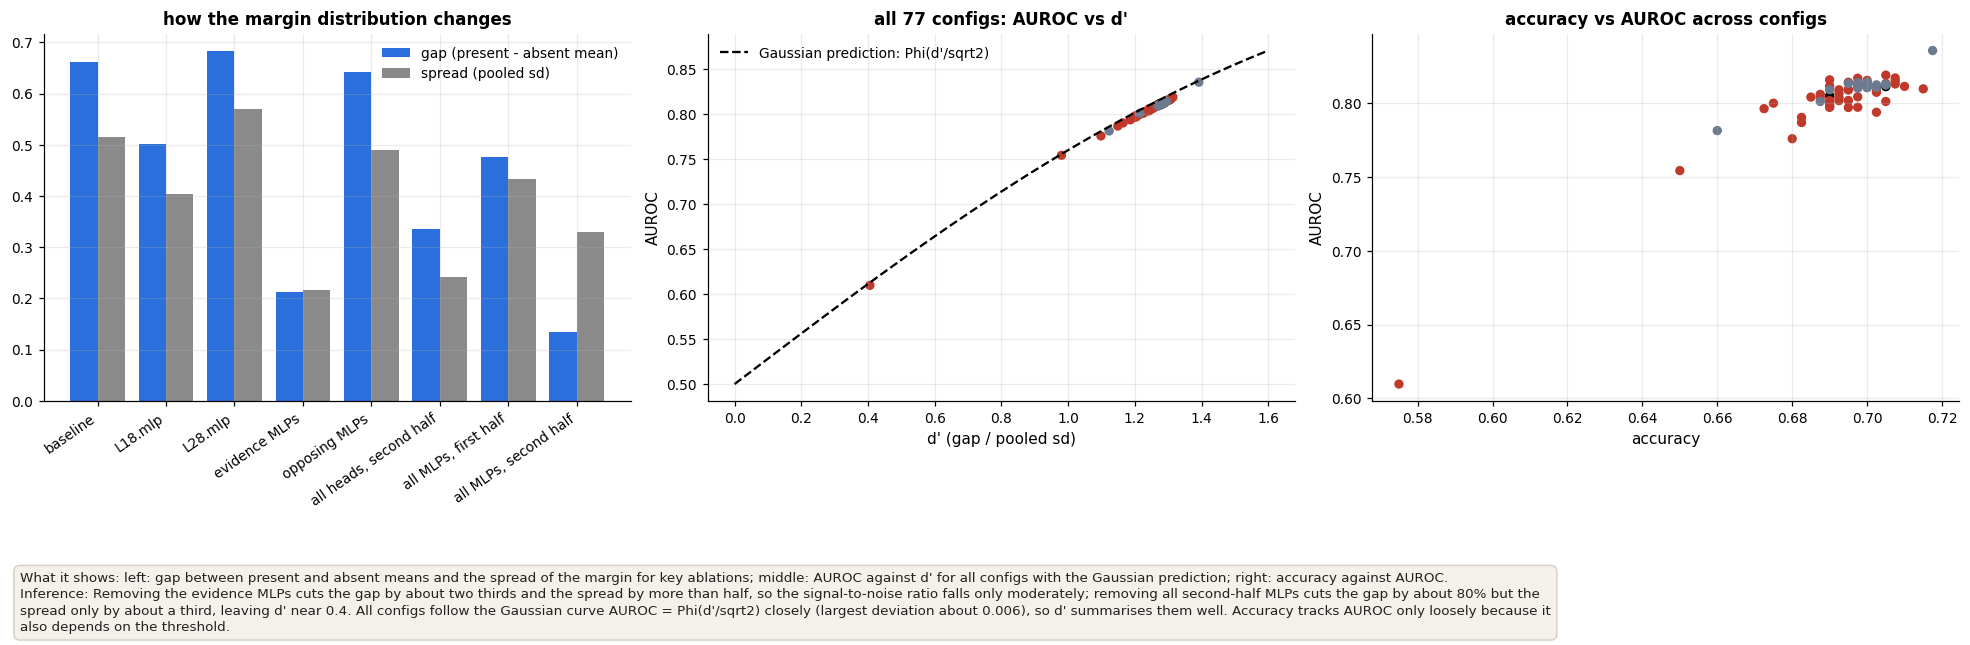

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/mlp_localisation_table.csv
  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/mlp_localisation.npz


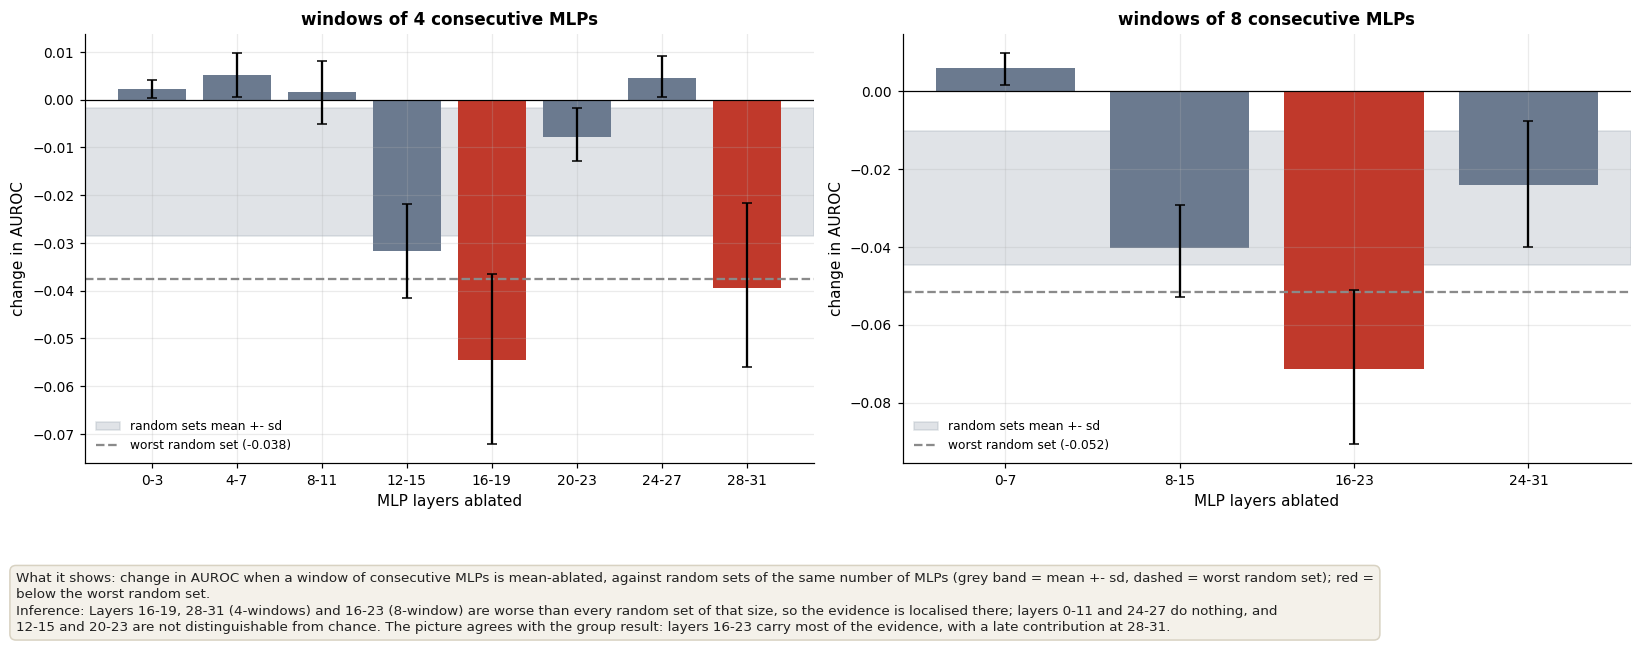

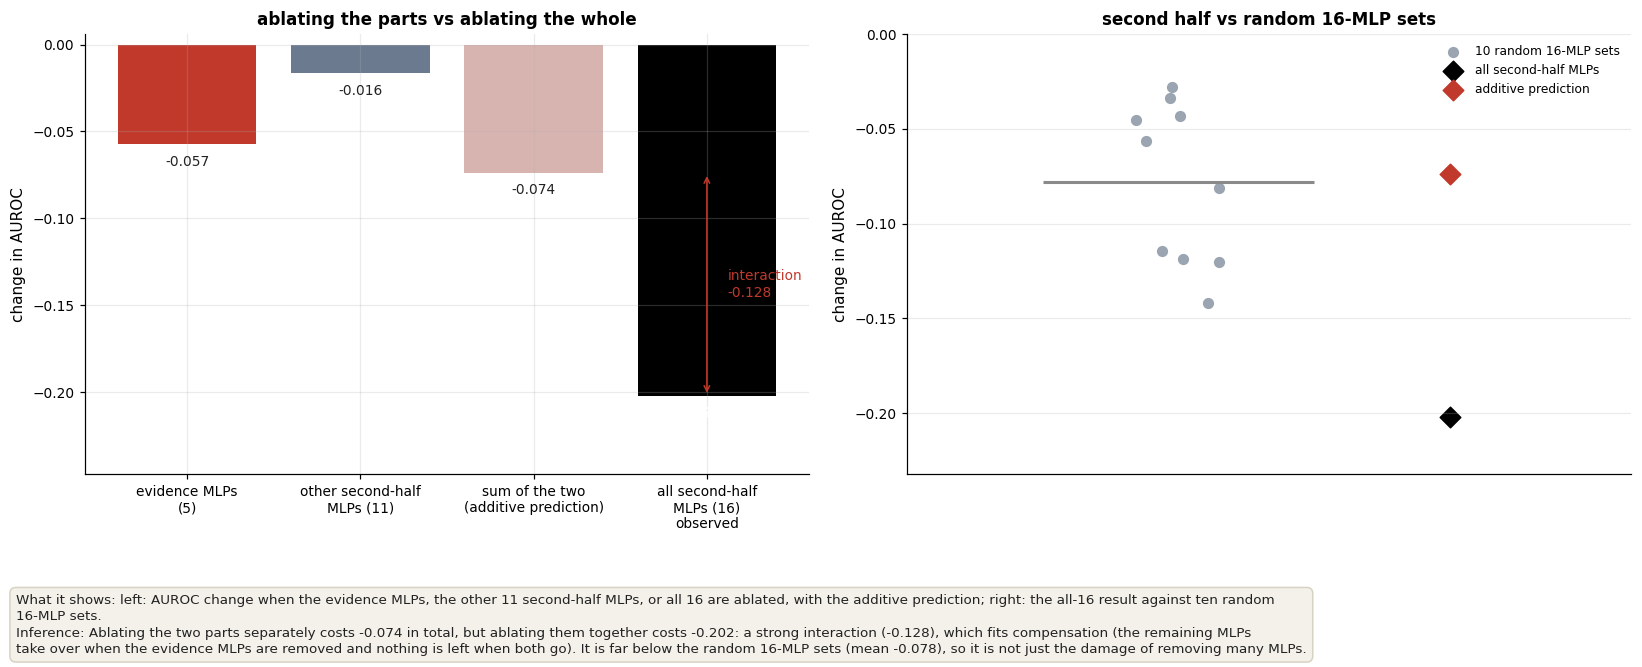

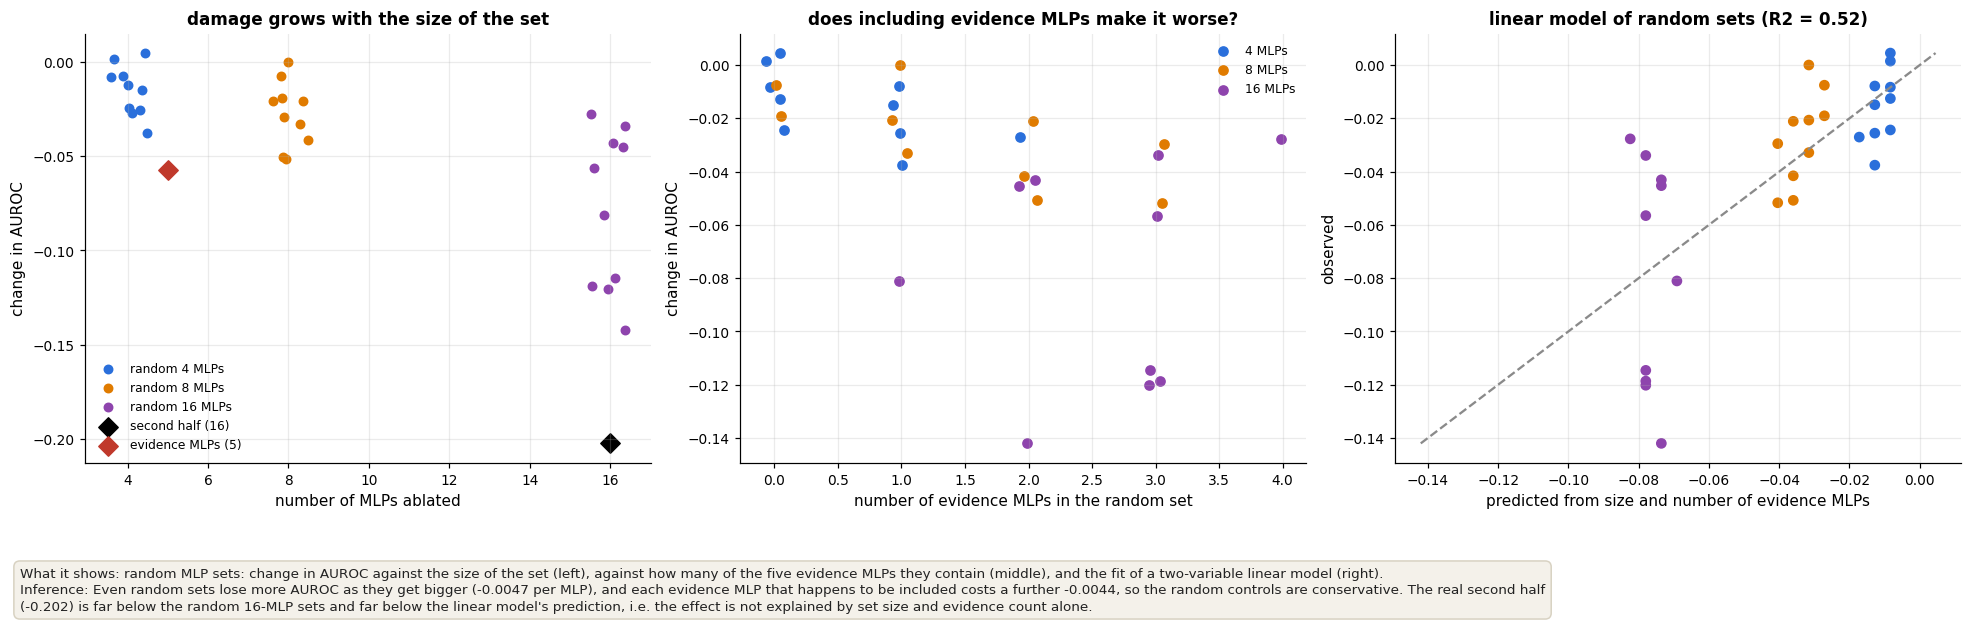

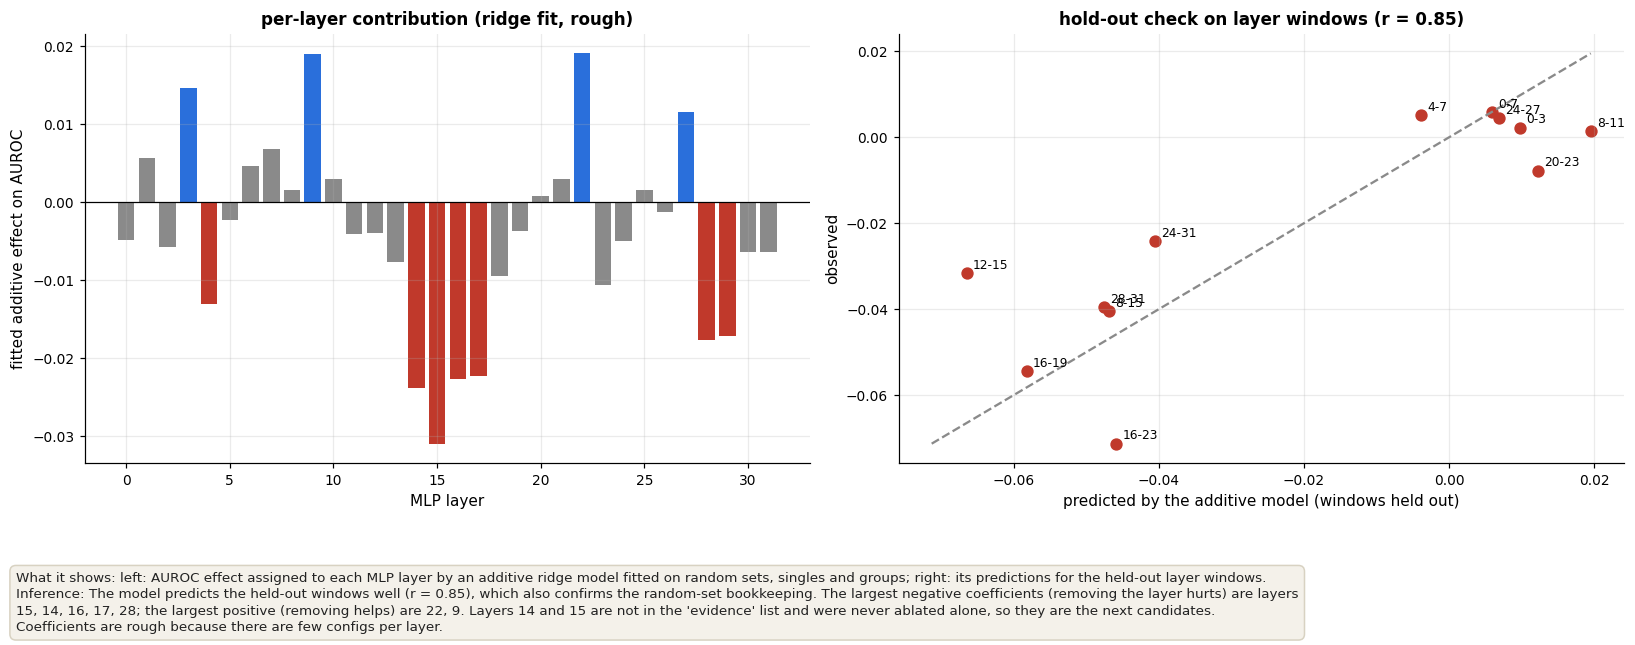

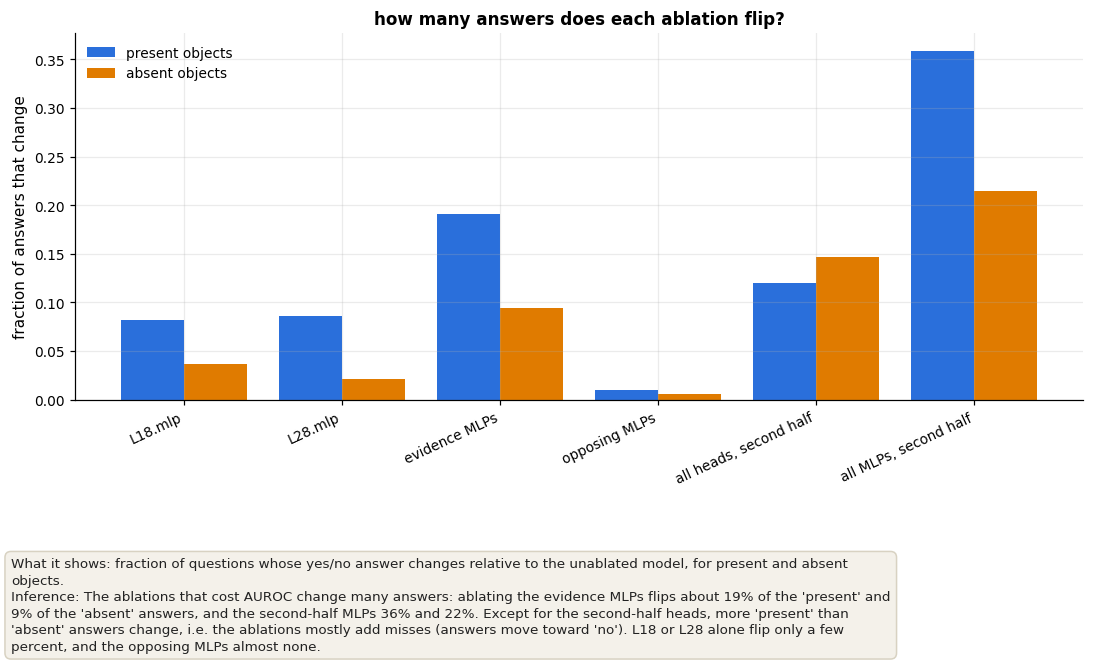

In [5]:
# GRAPHS 6. step 6 (mean-ablation) and 6x (layer localisation). Needs meanablation_table.csv, meanablation_results.npz and (optional) mlp_localisation_table.csv / mlp_localisation.npz
def _r6(): return load("meanablation_table.csv")
def _ld6():
    z = load("meanablation_results.npz"); lab = list(z["labels"]); return z["LD"], lab, np.array(z["gt"]).astype(str) == "yes"
def _rx():
    t = load("mlp_localisation_table.csv"); z = load("mlp_localisation.npz"); return t, z["LD"], list(z["labels"])
@run
def g6_singles_forest():
    R = _r6(); s = R[R.group == "single"].sort_values("d_auroc"); fig, ax = plt.subplots(1, 1, figsize=(9, 7)); y = np.arange(len(s))
    c = [COL["mlp"] if "mlp" in l else COL["head"] for l in s.label]
    ax.errorbar(s.d_auroc, y, xerr=[s.d_auroc - s.ci_lo, s.ci_hi - s.d_auroc], fmt="none", ecolor=COL["grey"], capsize=3, zorder=1); ax.scatter(s.d_auroc, y, c=c, s=55, zorder=3); ax.axvline(0, c="k", lw=.8)
    ax.set_yticks(y); ax.set_yticklabels(s.label); ax.set_xlabel("change in AUROC after mean-ablating the component (95% paired-bootstrap CI)"); ax.set_title("step 6: single components"); b = R.iloc[0].auroc
    finish(fig, "g6_singles_forest", f"change in AUROC (baseline {b:.3f}) when one head (grey) or MLP (red) is replaced by its mean activation; bars are 95% bootstrap intervals.",
           "Every single component has a small effect: the largest drops are L28.mlp (-0.015) and L16.mlp (-0.012); L18.mlp, the biggest contributor in attribution patching, costs only -0.008 and its interval nearly touches zero. Heads are all within +-0.007. No single component is necessary for telling present from absent, which suggests redundancy or compensation.")
@run
def g6_groups_vs_random():
    R = _r6(); gl = ["evidence MLPs", "opposing MLPs", "answer-reactive MLPs", "evidence heads", "bias heads"]; fig, ax = plt.subplots(1, 1, figsize=(11, 5))
    for i, g in enumerate(gl):
        rnd = R[(R.group == "random") & (R.gname == g)].d_auroc.values; real = R[(R.group == "group") & (R.gname == g)].iloc[0]; jit = (np.random.default_rng(i).random(len(rnd)) - .5) * .25
        ax.scatter(i + jit, rnd, c=COL["rnd"], s=30, label="10 random matched sets" if i == 0 else None); ax.hlines(rnd.mean(), i - .25, i + .25, color=COL["grey"], lw=2)
        ax.errorbar([i + .35], [real.d_auroc], yerr=[[real.d_auroc - real.ci_lo], [real.ci_hi - real.d_auroc]], fmt="D", c=COL["mlp"], ms=9, capsize=4, label="real group (95% CI)" if i == 0 else None)
    ax.axhline(0, c="k", lw=.8); ax.set_xticks(range(len(gl))); ax.set_xticklabels([f"{g}\n(n={int(R[(R.group == 'group') & (R.gname == g)].n_comp.iloc[0])})" for g in gl]); ax.set_ylabel("change in AUROC"); ax.set_title("step 6: groups against size-matched random controls"); ax.legend(loc="lower right")
    ev = R[(R.group == "group") & (R.gname == "evidence MLPs")].iloc[0]; rr = R[(R.group == "random") & (R.gname == "evidence MLPs")].d_auroc
    finish(fig, "g6_groups_vs_random", "change in AUROC when a whole group is mean-ablated (red diamond) compared with 10 random sets of the same size and type (grey dots; line = their mean).",
           f"The five evidence MLPs lose {ev.d_auroc:+.3f} AUROC, far below every random 5-MLP set (worst {rr.min():+.3f}), so this group matters beyond chance. The opposing MLPs are neutral or slightly positive, the answer-reactive pair is mildly harmful, and the evidence heads are only marginal; the bias heads do nothing. Random sets can also reduce AUROC a little, which is why the controls matter.")
@run
def g6_halves():
    R = _r6(); lab = ["all heads, first half", "all heads, second half", "all MLPs, first half", "all MLPs, second half"]; s = R.set_index("label").loc[lab]; fig, ax = plt.subplots(1, 1, figsize=(9, 4.6))
    c = [COL["head"], COL["head"], COL["mlp"], COL["mlp"]]; ax.bar(range(4), s.d_auroc, yerr=[s.d_auroc - s.ci_lo, s.ci_hi - s.d_auroc], color=c, capsize=4); ax.axhline(0, c="k", lw=.8)
    ax.set_xticks(range(4)); ax.set_xticklabels(["heads\nlayers 0-15", "heads\nlayers 16-31", "MLPs\nlayers 0-15", "MLPs\nlayers 16-31"]); ax.set_ylabel("change in AUROC"); ax.set_title("mean-ablating half of the network")
    for i, v in enumerate(s.d_auroc): ax.text(i, v + (.006 if v > 0 else -.014), f"{v:+.3f}", ha="center")
    finish(fig, "g6_halves", "change in AUROC when all heads or all MLPs in the first or second half of the layers are mean-ablated at the last position.",
           "The big effect is the second-half MLPs (AUROC drops by 0.20 to 0.61). The same half of the heads makes the model slightly better (+0.024), i.e. those heads add noise at the last token, and the first-half MLPs and heads cost only about 0.03-0.04. The image evidence that is visible at the last position passes through the late MLPs.")
@run
def g6_roc_and_hist():
    LD, lab, y = _ld6(); fig, ax = plt.subplots(1, 4, figsize=(20, 4.6)); sel = [("baseline", "k"), ("L18.mlp", COL["mlp"]), ("evidence MLPs", COL["ev"]), ("all heads, second half", COL["head"]), ("all MLPs, second half", COL["br"])]
    for n, c in sel:
        f, t = roc(LD[:, lab.index(n)], y); ax[0].plot(f, t, c=c, label=f"{n}: {auc(LD[:, lab.index(n)], y):.3f}")
    ax[0].plot([0, 1], [0, 1], c=COL["grey"], ls=":"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate"); ax[0].set_title("ROC curves"); ax[0].legend(loc="lower right", fontsize=8)
    for a, n in zip(ax[1:], ["baseline", "evidence MLPs", "all MLPs, second half"]):
        d = LD[:, lab.index(n)]; b = np.linspace(np.percentile(LD, 0.5), np.percentile(LD, 99.5), 36)
        a.hist(d[y], b, alpha=.65, color=COL["pres"], label="present"); a.hist(d[~y], b, alpha=.65, color=COL["absn"], label="absent"); a.axvline(0, c="k", lw=.8); a.set_xlabel("logit(Yes) - logit(No)"); a.set_title(f"{n}: AUROC {auc(d, y):.3f}"); a.legend()
    finish(fig, "g6_roc_and_hist", "ROC curves of selected ablations (left) and the margin distributions for present and absent objects in the baseline, after ablating the evidence MLPs, and after ablating all second-half MLPs.",
           "Ablating the evidence MLPs shrinks the margin distribution to about 40% of its width and pulls the two classes together; ablating all second-half MLPs leaves two heavily overlapping distributions. The ROC curves show the same ordering. The ablation removes variation in the margin, and with it most of the class separation.")
@run
def g6_gap_sd_dprime():
    LD, lab, y = _ld6(); R = _r6(); st = []
    for j, l in enumerate(lab):
        d = LD[:, j]; mp, ma = d[y].mean(), d[~y].mean(); sd = np.sqrt((d[y].var(ddof=1) + d[~y].var(ddof=1)) / 2); st.append((l, mp - ma, sd, (mp - ma) / sd, auc(d, y)))
    S = pd.DataFrame(st, columns=["label", "gap", "sd", "dprime", "auroc"]); key = ["baseline", "L18.mlp", "L28.mlp", "evidence MLPs", "opposing MLPs", "all heads, second half", "all MLPs, first half", "all MLPs, second half"]; k = S.set_index("label").loc[key]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); x = np.arange(len(key)); ax[0].bar(x - .2, k.gap, .4, color=COL["pres"], label="gap (present - absent mean)"); ax[0].bar(x + .2, k.sd, .4, color=COL["grey"], label="spread (pooled sd)"); ax[0].set_xticks(x); ax[0].set_xticklabels(key, rotation=35, ha="right"); ax[0].set_title("how the margin distribution changes"); ax[0].legend()
    c = [COL["head"] if "head" in l else COL["mlp"] if ("mlp" in l.lower() or "MLP" in l) else "k" for l in S.label]; ax[1].scatter(S.dprime, S.auroc, c=c, s=26); xs = np.linspace(0, 1.6, 100); ax[1].plot(xs, norm.cdf(xs / np.sqrt(2)), c="k", ls="--", label="Gaussian prediction: Phi(d'/sqrt2)"); ax[1].set_xlabel("d' (gap / pooled sd)"); ax[1].set_ylabel("AUROC"); ax[1].set_title("all 77 configs: AUROC vs d'"); ax[1].legend()
    ax[2].scatter(R.acc0, R.auroc, c=c, s=26); ax[2].set_xlabel("accuracy"); ax[2].set_ylabel("AUROC"); ax[2].set_title("accuracy vs AUROC across configs")
    finish(fig, "g6_gap_sd_dprime", "left: gap between present and absent means and the spread of the margin for key ablations; middle: AUROC against d' for all configs with the Gaussian prediction; right: accuracy against AUROC.",
           "Removing the evidence MLPs cuts the gap by about two thirds and the spread by more than half, so the signal-to-noise ratio falls only moderately; removing all second-half MLPs cuts the gap by about 80% but the spread only by about a third, leaving d' near 0.4. All configs follow the Gaussian curve AUROC = Phi(d'/sqrt2) closely (largest deviation about 0.006), so d' summarises them well. Accuracy tracks AUROC only loosely because it also depends on the threshold.")
@run
def g6_windows_vs_random():
    t, LDX, lab = _rx(); R = _r6(); fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    for a, sz in zip(ax, (4, 8)):
        w = t[(t.group == "window") & (t["size"] == sz)]; rnd = t[(t.group == "random") & (t["size"] == sz)].d_auroc; x = np.arange(len(w)); a.axhspan(rnd.mean() - rnd.std(), rnd.mean() + rnd.std(), color=COL["rnd"], alpha=.3, label="random sets mean +- sd"); a.axhline(rnd.min(), c=COL["grey"], ls="--", label=f"worst random set ({rnd.min():+.3f})")
        a.bar(x, w.d_auroc, yerr=[w.d_auroc - w.ci_lo, w.ci_hi - w.d_auroc], color=[COL["ev"] if v < rnd.min() else COL["head"] for v in w.d_auroc], capsize=3); a.axhline(0, c="k", lw=.8)
        a.set_xticks(x); a.set_xticklabels([l.replace("window MLPs ", "") for l in w.label]); a.set_xlabel("MLP layers ablated"); a.set_ylabel("change in AUROC"); a.set_title(f"windows of {sz} consecutive MLPs"); a.legend(loc="lower left", fontsize=8)
    finish(fig, "g6_windows_vs_random", "change in AUROC when a window of consecutive MLPs is mean-ablated, against random sets of the same number of MLPs (grey band = mean +- sd, dashed = worst random set); red = below the worst random set.",
           "Layers 16-19, 28-31 (4-windows) and 16-23 (8-window) are worse than every random set of that size, so the evidence is localised there; layers 0-11 and 24-27 do nothing, and 12-15 and 20-23 are not distinguishable from chance. The picture agrees with the group result: layers 16-23 carry most of the evidence, with a late contribution at 28-31.")
@run
def g6_interaction():
    t, LDX, lab = _rx(); R = _r6(); S = R.set_index("label"); ev = S.loc["evidence MLPs", "d_auroc"]; h2 = S.loc["all MLPs, second half", "d_auroc"]; rest = t[t.group == "special"].d_auroc.iloc[0]; r16 = t[(t.group == "random") & (t["size"] == 16)].d_auroc
    fig, ax = plt.subplots(1, 2, figsize=(15, 5)); vals = [ev, rest, ev + rest, h2]; names = ["evidence MLPs\n(5)", "other second-half\nMLPs (11)", "sum of the two\n(additive prediction)", "all second-half\nMLPs (16)\nobserved"]
    ax[0].bar(range(4), vals, color=[COL["ev"], COL["head"], "#d8b4b0", "k"]); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(names); ax[0].set_ylabel("change in AUROC"); ax[0].set_title("ablating the parts vs ablating the whole")
    ax[0].set_ylim(min(vals) - .045, 0.006)
    for i, v in enumerate(vals): ax[0].text(i, v - .006, f"{v:+.3f}", ha="center", va="top", color="white" if i == 3 else COL["ink"], fontweight="bold" if i == 3 else None)
    ax[0].annotate("", xy=(3, h2), xytext=(3, ev + rest), arrowprops=dict(arrowstyle="<->", color=COL["bad"])); ax[0].text(3.12, (h2 + ev + rest) / 2, f"interaction\n{h2 - ev - rest:+.3f}", color=COL["bad"], va="center")
    ax[1].scatter(np.zeros(len(r16)) + (np.random.default_rng(1).random(len(r16)) - .5) * .2, r16, c=COL["rnd"], s=40, label="10 random 16-MLP sets"); ax[1].hlines(r16.mean(), -.3, .3, color=COL["grey"], lw=2); ax[1].scatter([.6], [h2], c="k", marker="D", s=90, label="all second-half MLPs"); ax[1].scatter([.6], [ev + rest], c=COL["ev"], marker="D", s=90, label="additive prediction")
    ax[1].set_xlim(-.6, 1.0); ax[1].set_xticks([]); ax[1].set_ylabel("change in AUROC"); ax[1].set_title("second half vs random 16-MLP sets"); ax[1].set_ylim(min(h2, r16.min()) - .03, 0.0); ax[1].legend(loc="upper right", fontsize=8)
    finish(fig, "g6_interaction", "left: AUROC change when the evidence MLPs, the other 11 second-half MLPs, or all 16 are ablated, with the additive prediction; right: the all-16 result against ten random 16-MLP sets.",
           f"Ablating the two parts separately costs {ev + rest:+.3f} in total, but ablating them together costs {h2:+.3f}: a strong interaction ({h2 - ev - rest:+.3f}), which fits compensation (the remaining MLPs take over when the evidence MLPs are removed and nothing is left when both go). It is far below the random 16-MLP sets (mean {r16.mean():+.3f}), so it is not just the damage of removing many MLPs.")
@run
def g6_random_set_scaling():
    t, LDX, lab = _rx(); R = _r6(); EV = {16, 17, 18, 20, 23}; allm = [f"L{l}.mlp" for l in range(32)]
    def mem(r):
        sd = int(r.label.split("#")[1]); return {int(m[1:].split(".")[0]) for m in random.Random(9100 + 31 * r["size"] + sd).sample(allm, r["size"])}
    s = t[t.group == "random"].copy(); s["n_ev"] = [len(mem(r) & EV) for _, r in s.iterrows()]; fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); cc = {4: COL["pres"], 8: COL["absn"], 16: COL["br"]}
    for sz, d in s.groupby("size"): ax[0].scatter(np.full(len(d), sz) + (np.random.default_rng(sz).random(len(d)) - .5) * 1.0, d.d_auroc, c=cc[sz], s=30, label=f"random {sz} MLPs")
    ax[0].scatter([16], [R.set_index("label").loc["all MLPs, second half", "d_auroc"]], c="k", marker="D", s=80, label="second half (16)"); ax[0].scatter([5], [R.set_index("label").loc["evidence MLPs", "d_auroc"]], c=COL["ev"], marker="D", s=80, label="evidence MLPs (5)")
    ax[0].set_xlabel("number of MLPs ablated"); ax[0].set_ylabel("change in AUROC"); ax[0].set_title("damage grows with the size of the set"); ax[0].legend(fontsize=8)
    for sz, d in s.groupby("size"): ax[1].scatter(d.n_ev + (np.random.default_rng(sz + 1).random(len(d)) - .5) * .15, d.d_auroc, c=cc[sz], s=36, label=f"{sz} MLPs")
    ax[1].set_xlabel("number of evidence MLPs in the random set"); ax[1].set_ylabel("change in AUROC"); ax[1].set_title("does including evidence MLPs make it worse?"); ax[1].legend(fontsize=8)
    from numpy.linalg import lstsq; Aa = np.c_[np.ones(len(s)), s["size"], s.n_ev]; be = lstsq(Aa, s.d_auroc, rcond=None)[0]; pr = Aa @ be; ax[2].scatter(pr, s.d_auroc, c=[cc[v] for v in s["size"]], s=36); lim = [min(pr.min(), s.d_auroc.min()), max(pr.max(), s.d_auroc.max())]; ax[2].plot(lim, lim, c=COL["grey"], ls="--")
    ax[2].set_xlabel("predicted from size and number of evidence MLPs"); ax[2].set_ylabel("observed"); ax[2].set_title(f"linear model of random sets (R2 = {1 - ((s.d_auroc - pr) ** 2).sum() / ((s.d_auroc - s.d_auroc.mean()) ** 2).sum():.2f})")
    finish(fig, "g6_random_set_scaling", "random MLP sets: change in AUROC against the size of the set (left), against how many of the five evidence MLPs they contain (middle), and the fit of a two-variable linear model (right).",
           f"Even random sets lose more AUROC as they get bigger ({be[1]:+.4f} per MLP), and each evidence MLP that happens to be included costs a further {be[2]:+.4f}, so the random controls are conservative. The real second half (-0.202) is far below the random 16-MLP sets and far below the linear model's prediction, i.e. the effect is not explained by set size and evidence count alone.")
@run
def g6_layer_coefficients():
    t, LDX, lab = _rx(); R = _r6(); S = R.set_index("label"); EVl = [16, 17, 18, 20, 23]; allm = [f"L{l}.mlp" for l in range(32)]; rows = []
    def mem(r):
        if r.group == "window": lo, hi = map(int, r.label.split()[-1].split("-")); return list(range(lo, hi + 1))
        if r.group == "special": return [l for l in range(16, 32) if l not in EVl]
        if r.group == "random": return [int(m[1:].split(".")[0]) for m in random.Random(9100 + 31 * r["size"] + int(r.label.split("#")[1])).sample(allm, r["size"])]
        pool = [m for m in allm if int(m[1:].split(".")[0]) not in EVl]; return [int(m[1:].split(".")[0]) for m in random.Random(9500 + int(r.label.split("#")[1])).sample(pool, 11)]
    for _, r in t.iterrows():
        if r.group != "window": rows.append((mem(r), r.d_auroc))
    for l in (16, 17, 18, 20, 23, 21, 24, 27, 28, 30): rows.append(([l], S.loc[f"L{l}.mlp", "d_auroc"]))
    for k, m in {"evidence MLPs": EVl, "opposing MLPs": [21, 24, 27], "answer-reactive MLPs": [28, 30], "all MLPs, first half": list(range(16))}.items(): rows.append((m, S.loc[k, "d_auroc"]))
    M = np.zeros((len(rows), 32)); y = np.array([r[1] for r in rows])
    for i, r in enumerate(rows): M[i, r[0]] = 1
    b = np.linalg.solve(M.T @ M + .02 * np.eye(32), M.T @ y); wins = t[t.group == "window"]; pw = [float(sum(b[l] for l in mem(r))) for _, r in wins.iterrows()]; r_ = np.corrcoef(pw, wins.d_auroc)[0, 1]
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8)); ax[0].bar(range(32), b, color=[COL["ev"] if v < -.012 else (COL["op"] if v > .008 else COL["grey"]) for v in b]); ax[0].axhline(0, c="k", lw=.8); ax[0].set_xlabel("MLP layer"); ax[0].set_ylabel("fitted additive effect on AUROC"); ax[0].set_title("per-layer contribution (ridge fit, rough)")
    ax[1].scatter(pw, wins.d_auroc, c=COL["mlp"], s=50)
    for p, o, l in zip(pw, wins.d_auroc, wins.label): ax[1].annotate(l.replace("window MLPs ", ""), (p, o), xytext=(4, 3), textcoords="offset points", fontsize=8)
    lim = [min(min(pw), wins.d_auroc.min()), max(max(pw), wins.d_auroc.max())]; ax[1].plot(lim, lim, c=COL["grey"], ls="--"); ax[1].set_xlabel("predicted by the additive model (windows held out)"); ax[1].set_ylabel("observed"); ax[1].set_title(f"hold-out check on layer windows (r = {r_:.2f})")
    finish(fig, "g6_layer_coefficients", "left: AUROC effect assigned to each MLP layer by an additive ridge model fitted on random sets, singles and groups; right: its predictions for the held-out layer windows.",
           f"The model predicts the held-out windows well (r = {r_:.2f}), which also confirms the random-set bookkeeping. The largest negative coefficients (removing the layer hurts) are layers {', '.join(str(int(i)) for i in np.argsort(b)[:5])}; the largest positive (removing helps) are {', '.join(str(int(i)) for i in np.argsort(-b)[:2])}. Layers 14 and 15 are not in the 'evidence' list and were never ablated alone, so they are the next candidates. Coefficients are rough because there are few configs per layer.")
@run
def g6_flips():
    LD, lab, y = _ld6(); fig, ax = plt.subplots(1, 1, figsize=(10, 4.6)); key = ["L18.mlp", "L28.mlp", "evidence MLPs", "opposing MLPs", "all heads, second half", "all MLPs, second half"]; b = LD[:, 0] > 0; x = np.arange(len(key))
    fp = [float(((LD[:, lab.index(k)] > 0) != b)[y].mean()) for k in key]; fa = [float(((LD[:, lab.index(k)] > 0) != b)[~y].mean()) for k in key]
    ax.bar(x - .2, fp, .4, color=COL["pres"], label="present objects"); ax.bar(x + .2, fa, .4, color=COL["absn"], label="absent objects"); ax.set_xticks(x); ax.set_xticklabels(key, rotation=25, ha="right"); ax.set_ylabel("fraction of answers that change"); ax.set_title("how many answers does each ablation flip?"); ax.legend()
    finish(fig, "g6_flips", "fraction of questions whose yes/no answer changes relative to the unablated model, for present and absent objects.",
           "The ablations that cost AUROC change many answers: ablating the evidence MLPs flips about 19% of the 'present' and 9% of the 'absent' answers, and the second-half MLPs 36% and 22%. Except for the second-half heads, more 'present' than 'absent' answers change, i.e. the ablations mostly add misses (answers move toward 'no'). L18 or L28 alone flip only a few percent, and the opposing MLPs almost none.")


## Step 7 (optional, after step 7 has run): patching sweeps (needs `patch_last_position.csv`, `patch_kv.csv`)

  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/patch_last_position.csv
  loaded /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/patch_kv.csv


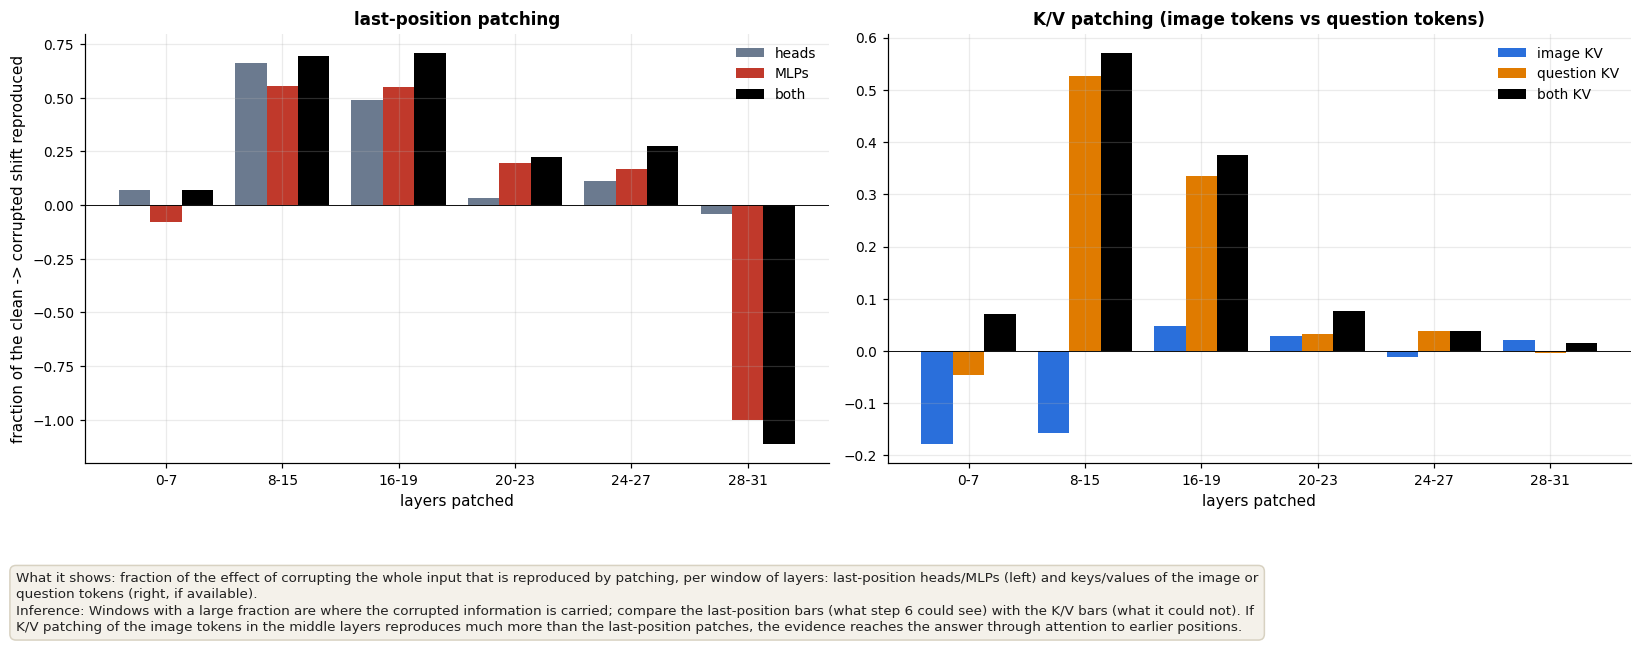

In [3]:
# GRAPHS 7 (optional, run after step 7): patching sweeps. Needs patch_last_position.csv and (noise / shuffle) patch_kv.csv
@run
def g7_patching():
    a = load("patch_last_position.csv"); kv = find("patch_kv.csv"); kvd = load("patch_kv.csv") if kv else None; n = 2 if kvd is not None else 1; fig, ax = plt.subplots(1, n, figsize=(7.5 * n, 4.8), squeeze=False); x = np.arange(len(a)); w = .27
    for k, (c, nm) in enumerate(zip([COL["head"], COL["mlp"], "k"], ["heads", "MLPs", "both"])): ax[0, 0].bar(x + (k - 1) * w, a[f"{nm}: frac"], w, color=c, label=nm)
    ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(a.layers); ax[0, 0].set_xlabel("layers patched"); ax[0, 0].set_ylabel("fraction of the clean -> corrupted shift reproduced"); ax[0, 0].set_title("last-position patching"); ax[0, 0].legend(); ax[0, 0].axhline(0, c="k", lw=.6)
    if kvd is not None:
        for k, (c, nm) in enumerate(zip([COL["pres"], COL["absn"], "k"], ["image KV", "question KV", "both KV"])): ax[0, 1].bar(x + (k - 1) * w, kvd[f"{nm}: frac"], w, color=c, label=nm)
        ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(kvd.layers); ax[0, 1].set_xlabel("layers patched"); ax[0, 1].set_title("K/V patching (image tokens vs question tokens)"); ax[0, 1].legend(); ax[0, 1].axhline(0, c="k", lw=.6)
    finish(fig, "g7_patching", "fraction of the effect of corrupting the whole input that is reproduced by patching, per window of layers: last-position heads/MLPs (left) and keys/values of the image or question tokens (right, if available).",
           "Windows with a large fraction are where the corrupted information is carried; compare the last-position bars (what step 6 could see) with the K/V bars (what it could not). If K/V patching of the image tokens in the middle layers reproduces much more than the last-position patches, the evidence reaches the answer through attention to earlier positions.")
